<a href="https://colab.research.google.com/github/Arpi-27/NLP-experiments/blob/main/NLP_practical.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import nltk
import re

from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk import pos_tag

# Download required NLTK datasets
packages = [
    'punkt',
    'punkt_tab',
    'stopwords',
    'wordnet',
    'omw-1.4',
    'averaged_perceptron_tagger_eng'
]

for pkg in packages:
    nltk.download(pkg, quiet=True)

print("NLTK setup completed!")

NLTK setup completed!


In [ ]:
# 1.1 NLP TEXT PREPROCESSING AND ANALYSIS

# Step 1: Import Required Libraries

import nltk
import re
import string

from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk import pos_tag
from collections import Counter

# Step 2: Download Required NLTK Packages

packages = [
    'punkt',
    'punkt_tab',
    'stopwords',
    'wordnet',
    'omw-1.4',
    'averaged_perceptron_tagger_eng'
]

for package in packages:
    nltk.download(package, quiet=True)

print("All NLTK packages downloaded successfully!")

# Step 3: Input Text

text = """
Dr. Rao's research team is developing intelligent
chatbots, language translators and modern search engines!

The new AI systems are performing faster than expected.
Natural Language Processing helps computers understand
human language.

Visit https://example.com or contact nlp@lab.edu
for more information about NLP technologies.
"""

print("\n========== ORIGINAL TEXT ==========")
print(text)

# STEP 1: SENTENCE SEGMENTATION

sentences = sent_tokenize(text)

print("\n========== SENTENCE SEGMENTATION ==========")
print("Total Sentences:", len(sentences))

for index, sentence in enumerate(sentences, start=1):
    print(f"Sentence {index}: {sentence}")

# STEP 2: TEXT NORMALISATION

def normalize_text(sentence):

    # Remove URLs
    sentence = re.sub(r'https?://\S+|www\.\S+', '', sentence)

    # Remove email addresses
    sentence = re.sub(r'\S+@\S+', '', sentence)

    # Convert to lowercase
    sentence = sentence.lower()

    # Remove punctuation
    sentence = sentence.translate(
        str.maketrans('', '', string.punctuation)
    )

    # Remove extra spaces
    sentence = re.sub(r'\s+', ' ', sentence).strip()

    return sentence

normalized_sentences = [
    normalize_text(sentence) for sentence in sentences
]

print("\n========== NORMALISED TEXT ==========")

for index, sentence in enumerate(normalized_sentences, start=1):
    print(f"Sentence {index}: {sentence}")

# STEP 3: WORD TOKENISATION
# AND STOP-WORD REMOVAL

stop_words = set(stopwords.words('english'))

tokens = []

for sentence in normalized_sentences:
    tokens.extend(word_tokenize(sentence))

# Keep alphabetic words only
words = [word for word in tokens if word.isalpha()]

# Remove stop words
content_words = [
    word for word in words if word not in stop_words
]

print("\n========== TOKENISATION ==========")
print("Total Tokens:", len(tokens))
print("Filtered Words:", words)
print("Stop Words Removed:", len(words) - len(content_words))

print("\nFinal Content Words:")
print(content_words)

# STEP 4: STEMMING VS LEMMATISATION

stemmer = PorterStemmer()
lemmatizer = WordNetLemmatizer()

# Convert POS tags into WordNet format
def get_wordnet_pos(tag):

    if tag.startswith('J'):
        return wordnet.ADJ

    elif tag.startswith('V'):
        return wordnet.VERB

    elif tag.startswith('N'):
        return wordnet.NOUN

    elif tag.startswith('R'):
        return wordnet.ADV

    else:
        return wordnet.NOUN

# Apply POS tagging
pos_words = pos_tag(content_words)

print("\n========== STEMMING VS LEMMATISATION ==========")

print(f"{'WORD':<15}{'STEM':<15}{'LEMMA':<15}")

for word, tag in pos_words:

    stem = stemmer.stem(word)

    lemma = lemmatizer.lemmatize(
        word, get_wordnet_pos(tag)
    )

    print(f"{word:<15}{stem:<15}{lemma:<15}")

# STEP 5: VOCABULARY REDUCTION

original_vocabulary = set(words)
filtered_vocabulary = set(content_words)

stemmed_words = [
    stemmer.stem(word) for word in content_words
]

lemmatized_words = [
    lemmatizer.lemmatize(word, get_wordnet_pos(tag))
    for word, tag in pos_tag(content_words)
]

print("\n========== VOCABULARY ANALYSIS ==========")

print("Original Vocabulary Size:",
      len(original_vocabulary))

print("After Stop-Word Removal:",
      len(filtered_vocabulary))

print("After Stemming:",
      len(set(stemmed_words)))

print("After Lemmatization:",
      len(set(lemmatized_words)))

# STEP 6: MOST FREQUENT WORDS

word_frequency = Counter(content_words)

print("\n========== TOP 5 FREQUENT WORDS ==========")

for word, frequency in word_frequency.most_common(5):
    print(f"{word}: {frequency}")

# STEP 7: FINAL SUMMARY

print("\n========== FINAL SUMMARY ==========")

print("Total Sentences:", len(sentences))
print("Total Words:", len(words))
print("Words After Stop-Word Removal:", len(content_words))
print("Unique Original Words:", len(original_vocabulary))
print("Unique Stemmed Words:", len(set(stemmed_words)))
print("Unique Lemmatized Words:", len(set(lemmatized_words)))

print("\nNLP TEXT PREPROCESSING COMPLETED SUCCESSFULLY!")


All NLTK packages downloaded successfully!

========== ORIGINAL TEXT ==========

Dr. Rao's research team is developing intelligent
chatbots, language translators and modern search engines!

The new AI systems are performing faster than expected.
Natural Language Processing helps computers understand
human language.

Visit https://example.com or contact nlp@lab.edu
for more information about NLP technologies.


========== SENTENCE SEGMENTATION ==========
Total Sentences: 4
Sentence 1: 
Dr. Rao's research team is developing intelligent
chatbots, language translators and modern search engines!
Sentence 2: The new AI systems are performing faster than expected.
Sentence 3: Natural Language Processing helps computers understand
human language.
Sentence 4: Visit https://example.com or contact nlp@lab.edu
for more information about NLP technologies.

========== NORMALISED TEXT ==========
Sentence 1: dr raos research team is developing intelligent chatbots language translators and modern searc

Movie Reviews Dataset Loaded Successfully!

========== DATASET INFORMATION ==========
Total Reviews: 2000
Positive Reviews: 1000
Negative Reviews: 1000

========== DATA SPLITTING ==========
Training Samples: 1500
Testing Samples: 500

MODEL: Naive Bayes

Classification Report:
              precision    recall  f1-score   support

         neg      0.766     0.840     0.802       250
         pos      0.823     0.744     0.782       250

    accuracy                          0.792       500
   macro avg      0.795     0.792     0.792       500
weighted avg      0.795     0.792     0.792       500

Confusion Matrix:
[[210  40]
 [ 64 186]]

Evaluation Metrics:
Accuracy : 0.792
Precision: 0.823
Recall   : 0.744
F1 Score : 0.782

Cross Validation Scores: [0.78333333 0.84333333 0.84       0.84333333 0.82666667]
Average CV Accuracy: 0.827

MODEL: Logistic Regression

Classification Report:
              precision    recall  f1-score   support

         neg      0.845     0.848     0.846     

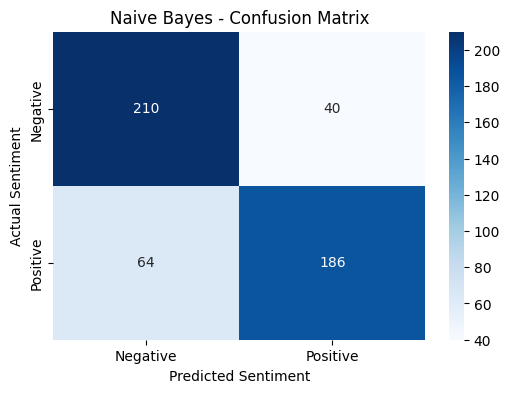

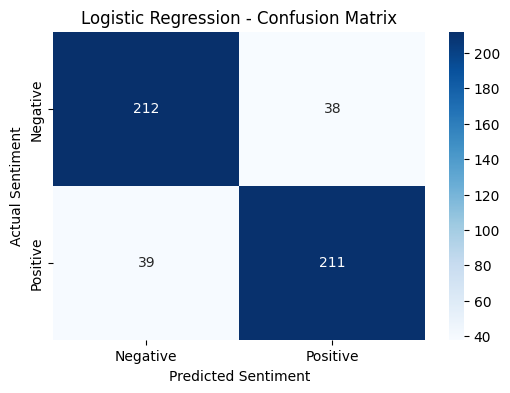

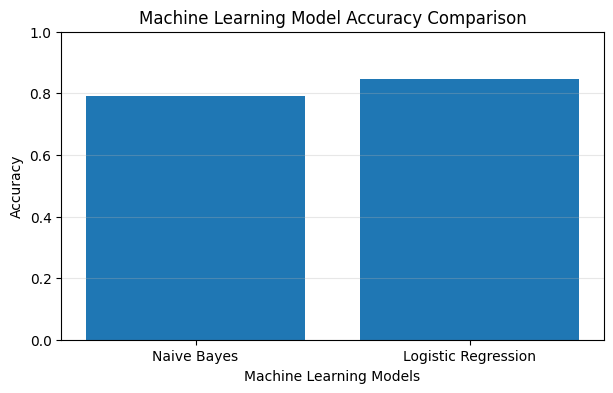


========== SENTIMENT WORD ANALYSIS ==========

Most Negative Words:
['wasted', 'schumacher', 'waste', 'worst', 'awful', 'seagal', 'boring', 'waste time', 'lame', 'ludicrous', 'just bad', 'insulting', 'stupid', 'bad movie', 'idiotic']

Most Positive Words:
['outstanding', 'wonderfully', 'anger', 'beautifully', 'damon', 'coen', 'crowe', 'gattaca', 'finest', 'matt damon', 'gump', 'stiller', 'breathtaking', 'taxi', 'political']

========== CUSTOM REVIEW PREDICTIONS ==========
Selected Model: Logistic Regression

Review: This movie was absolutely fantastic and amazing.
Predicted Sentiment: Positive

Review: The film was boring, disappointing and terrible.
Predicted Sentiment: Negative

Review: The acting was excellent and the story was beautiful.
Predicted Sentiment: Positive

Review: I disliked the movie because it was too slow.
Predicted Sentiment: Negative

FINAL SENTIMENT ANALYSIS SUMMARY
Total Dataset: 2000
Training Data: 1500
Testing Data: 500

Model: Naive Bayes
Accuracy: 79.2 %
F1 

In [ ]:
# 1.2 SENTIMENT ANALYSIS USING MACHINE LEARNING

# STEP 1: IMPORT REQUIRED LIBRARIES

import nltk
import random
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.corpus import movie_reviews

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.model_selection import (
    train_test_split,
    cross_val_score,
    StratifiedKFold
)

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

from sklearn.pipeline import make_pipeline

# STEP 2: DOWNLOAD DATASET

nltk.download('movie_reviews', quiet=True)

print("Movie Reviews Dataset Loaded Successfully!")

# STEP 3: LOAD AND PREPARE DATASET

documents = []

for category in movie_reviews.categories():

    for file_id in movie_reviews.fileids(category):

        review = movie_reviews.raw(file_id)

        documents.append((review, category))

# Shuffle dataset
random.seed(42)
random.shuffle(documents)

X = [review for review, label in documents]
y = [label for review, label in documents]

print("\n========== DATASET INFORMATION ==========")

print("Total Reviews:", len(documents))
print("Positive Reviews:", y.count('pos'))
print("Negative Reviews:", y.count('neg'))

# STEP 4: SPLIT DATASET INTO TRAINING AND TESTING

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("\n========== DATA SPLITTING ==========")

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))

# STEP 5: CREATE TF-IDF FEATURE EXTRACTION PIPELINE

def create_model(classifier):

    pipeline = make_pipeline(

        TfidfVectorizer(
            stop_words='english',
            min_df=3,
            max_df=0.95,
            ngram_range=(1, 2),
            sublinear_tf=True,
            max_features=10000
        ),

        classifier
    )

    return pipeline


# Initialize Machine Learning Models

models = {

    "Naive Bayes": create_model(
        MultinomialNB(alpha=0.5)
    ),

    "Logistic Regression": create_model(
        LogisticRegression(
            max_iter=1500,
            C=2.0,
            random_state=42
        )
    )
}

# STEP 6: TRAIN AND EVALUATE MODELS

results = {}

for model_name, model in models.items():

    print("\n" + "=" * 65)
    print("MODEL:", model_name)
    print("=" * 65)

    # Train model
    model.fit(X_train, y_train)

    # Make predictions
    predictions = model.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, predictions)

    precision = precision_score(
        y_test, predictions, pos_label='pos'
    )

    recall = recall_score(
        y_test, predictions, pos_label='pos'
    )

    f1 = f1_score(
        y_test, predictions, pos_label='pos'
    )

    # Store results
    results[model_name] = {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    }

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        predictions,
        digits=3
    ))

    print("Confusion Matrix:")
    print(confusion_matrix(
        y_test,
        predictions,
        labels=['neg', 'pos']
    ))

    print("\nEvaluation Metrics:")
    print("Accuracy :", round(accuracy, 3))
    print("Precision:", round(precision, 3))
    print("Recall   :", round(recall, 3))
    print("F1 Score :", round(f1, 3))

    # 5-fold cross validation on training data
    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    cv_scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring='accuracy'
    )

    print("\nCross Validation Scores:", cv_scores)
    print("Average CV Accuracy:", round(cv_scores.mean(), 3))

# STEP 7: COMPARE BOTH MACHINE LEARNING MODELS

print("\n========== MODEL COMPARISON ==========")

for name, metrics in results.items():

    print("\n", name)

    for metric, value in metrics.items():

        print(metric, ":", round(value, 3))

# STEP 8: CONFUSION MATRIX VISUALISATION

for model_name, model in models.items():

    predictions = model.predict(X_test)

    matrix = confusion_matrix(
        y_test,
        predictions,
        labels=['neg', 'pos']
    )

    plt.figure(figsize=(6, 4))

    sns.heatmap(
        matrix,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['Negative', 'Positive'],
        yticklabels=['Negative', 'Positive']
    )

    plt.title(model_name + " - Confusion Matrix")
    plt.xlabel("Predicted Sentiment")
    plt.ylabel("Actual Sentiment")

    plt.show()
# STEP 9: ACCURACY COMPARISON GRAPH

model_names = list(results.keys())

accuracy_values = [
    results[name]['Accuracy']
    for name in model_names
]

plt.figure(figsize=(7, 4))

plt.bar(
    model_names,
    accuracy_values
)

plt.title("Machine Learning Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy")

plt.ylim(0, 1)
plt.grid(axis='y', alpha=0.3)

plt.show()

# STEP 10: IDENTIFY IMPORTANT SENTIMENT WORDS

naive_bayes = models["Naive Bayes"]

vectorizer = naive_bayes.named_steps['tfidfvectorizer']

classifier = naive_bayes.named_steps['multinomialnb']

feature_names = vectorizer.get_feature_names_out()

# Identify class indexes automatically
negative_index = list(classifier.classes_).index('neg')
positive_index = list(classifier.classes_).index('pos')

# Calculate word importance difference
word_difference = (
    classifier.feature_log_prob_[positive_index]
    - classifier.feature_log_prob_[negative_index]
)

sorted_indices = np.argsort(word_difference)

negative_words = [
    feature_names[index]
    for index in sorted_indices[:15]
]

positive_words = [
    feature_names[index]
    for index in sorted_indices[-15:][::-1]
]

print("\n========== SENTIMENT WORD ANALYSIS ==========")

print("\nMost Negative Words:")
print(negative_words)

print("\nMost Positive Words:")
print(positive_words)

# STEP 11: TEST WITH CUSTOM MOVIE REVIEWS
sample_reviews = [

    "This movie was absolutely fantastic and amazing.",

    "The film was boring, disappointing and terrible.",

    "The acting was excellent and the story was beautiful.",

    "I disliked the movie because it was too slow."

]

print("\n========== CUSTOM REVIEW PREDICTIONS ==========")

best_model_name = max(
    results,
    key=lambda name: results[name]['F1 Score']
)

best_model = models[best_model_name]

print("Selected Model:", best_model_name)

for review in sample_reviews:

    prediction = best_model.predict([review])[0]

    sentiment = (
        "Positive" if prediction == 'pos'
        else "Negative"
    )

    print("\nReview:", review)
    print("Predicted Sentiment:", sentiment)

# STEP 12: FINAL SUMMARY

print("\n" + "=" * 65)
print("FINAL SENTIMENT ANALYSIS SUMMARY")
print("=" * 65)

print("Total Dataset:", len(documents))
print("Training Data:", len(X_train))
print("Testing Data:", len(X_test))

for name, metrics in results.items():

    print("\nModel:", name)
    print("Accuracy:", round(metrics['Accuracy'] * 100, 2), "%")
    print("F1 Score:", round(metrics['F1 Score'], 3))

print("\nSENTIMENT ANALYSIS COMPLETED SUCCESSFULLY!")


NLTK Libraries Loaded Successfully!

========== ORIGINAL TEXT ==========

Natural Language Processing began in the 1950s
with machine translation experiments.

Early systems relied on hand-written rules created
by linguists. These rule-based systems were accurate
in narrow domains but difficult to scale.

In the 1990s, statistical methods replaced many rules
because large text collections became available.

Statistical models learn patterns of language from
annotated text and improve language understanding.

Today, neural networks power translation, search
engines and virtual assistants.

Modern language models are trained on billions
of words and perform complex language tasks.

The field continues to grow as new applications
appear in education, healthcare and technology.


========== SENTENCE SEGMENTATION ==========
Total Sentences: 8
1. 
Natural Language Processing began in the 1950s
with machine translation experiments.
2. Early systems relied on hand-written rules created
by ling

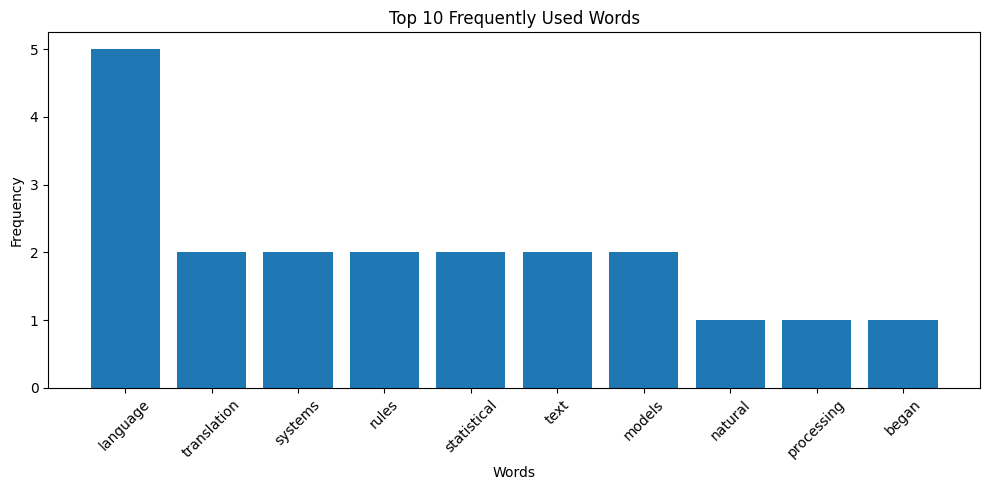

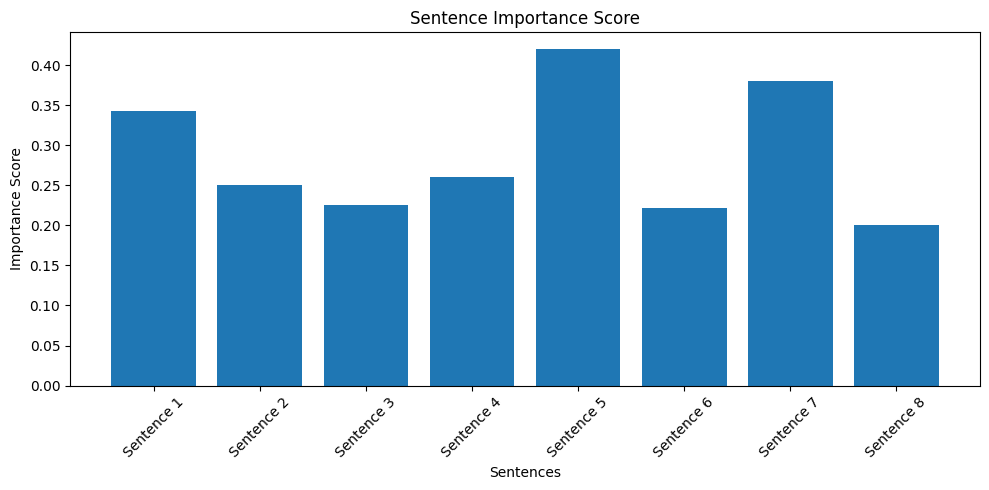


FINAL TEXT SUMMARIZATION REPORT
Total Sentences: 8
Total Content Words: 71
Unique Words: 61
Selected Summary Sentences: 3
Compression Ratio: 0.392
ROUGE-1 F1 Score: 0.218
ROUGE-2 F1 Score: 0.038

TEXT SUMMARIZATION COMPLETED SUCCESSFULLY!


In [ ]:
# 1.3 TEXT SUMMARIZATION USING NLP
# STEP 1: IMPORT REQUIRED LIBRARIES

import re
import nltk
import string
import matplotlib.pyplot as plt

from collections import Counter

from nltk.corpus import stopwords
from nltk.tokenize import sent_tokenize, word_tokenize

# STEP 2: DOWNLOAD NLTK DATASETS

packages = [
    'punkt',
    'punkt_tab',
    'stopwords'
]

for package in packages:
    nltk.download(package, quiet=True)

print("NLTK Libraries Loaded Successfully!")

# STEP 3: INPUT TEXT

text = """
Natural Language Processing began in the 1950s
with machine translation experiments.

Early systems relied on hand-written rules created
by linguists. These rule-based systems were accurate
in narrow domains but difficult to scale.

In the 1990s, statistical methods replaced many rules
because large text collections became available.

Statistical models learn patterns of language from
annotated text and improve language understanding.

Today, neural networks power translation, search
engines and virtual assistants.

Modern language models are trained on billions
of words and perform complex language tasks.

The field continues to grow as new applications
appear in education, healthcare and technology.
"""

reference = (
    "NLP evolved from hand-written rules to statistical "
    "methods and modern neural networks trained on large corpora."
)

print("\n========== ORIGINAL TEXT ==========")
print(text)

# STEP 4: SENTENCE SEGMENTATION

sentences = sent_tokenize(text)

print("\n========== SENTENCE SEGMENTATION ==========")

print("Total Sentences:", len(sentences))

for index, sentence in enumerate(sentences, start=1):
    print(f"{index}. {sentence}")

# STEP 5: TEXT PREPROCESSING

stop_words = set(stopwords.words('english'))

def preprocess(text):

    # Convert text to lowercase
    text = text.lower()

    # Remove special characters and numbers
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    # Tokenize words
    tokens = word_tokenize(text)

    # Remove stop words
    filtered_words = [
        word for word in tokens
        if word not in stop_words
    ]

    return filtered_words


all_words = preprocess(text)

print("\n========== TEXT PREPROCESSING ==========")

print("Total Content Words:", len(all_words))
print("Processed Words:", all_words)

# =====================================================
# STEP 6: WORD FREQUENCY ANALYSIS
# =====================================================

word_frequency = Counter(all_words)

max_frequency = max(word_frequency.values())

# Normalize word frequency
word_weights = {
    word: count / max_frequency
    for word, count in word_frequency.items()
}

print("\n========== WORD FREQUENCY TABLE ==========")

print(f"{'WORD':<20}{'FREQUENCY':<15}{'WEIGHT'}")

for word, count in word_frequency.most_common():

    print(
        f"{word:<20}{count:<15}"
        f"{word_weights[word]:.3f}"
    )

# =====================================================
# STEP 7: SENTENCE SCORING
# =====================================================

def calculate_sentence_score(sentence):

    words = preprocess(sentence)

    if not words:
        return 0

    total_score = sum(
        word_weights.get(word, 0)
        for word in words
    )

    # Average score to avoid long sentence bias
    return total_score / len(words)


sentence_scores = {
    sentence: calculate_sentence_score(sentence)
    for sentence in sentences
}

print("\n========== SENTENCE RANKING ==========")

ranked_sentences = sorted(
    sentence_scores.items(),
    key=lambda item: item[1],
    reverse=True
)

for rank, (sentence, score) in enumerate(
    ranked_sentences, start=1
):

    print(f"\nRank {rank}")
    print("Score:", round(score, 4))
    print("Sentence:", sentence)

# =====================================================
# STEP 8: GENERATE SUMMARY
# =====================================================

def generate_summary(number_of_sentences=3):

    number_of_sentences = max(
        1, min(number_of_sentences, len(sentences))
    )

    # Select highest-scoring sentences
    selected = {
        sentence
        for sentence, score in ranked_sentences[
            :number_of_sentences
        ]
    }

    # Maintain original sentence order
    summary_sentences = [
        sentence
        for sentence in sentences
        if sentence in selected
    ]

    return " ".join(summary_sentences)


summary = generate_summary(3)

print("\n========== GENERATED SUMMARY ==========")
print(summary)

# =====================================================
# STEP 9: SUMMARY STATISTICS
# =====================================================

original_word_count = len(text.split())
summary_word_count = len(summary.split())

compression_ratio = (
    summary_word_count / original_word_count
    if original_word_count else 0
)

reduction_percentage = (
    (1 - compression_ratio) * 100
)

print("\n========== SUMMARY STATISTICS ==========")

print("Original Word Count:", original_word_count)
print("Summary Word Count:", summary_word_count)

print("Compression Ratio:", round(compression_ratio, 3))

print(
    "Text Reduction:",
    round(reduction_percentage, 2), "%"
)

# =====================================================
# STEP 10: ROUGE EVALUATION
# =====================================================

def get_ngrams(text, n=1):

    words = re.findall(r'[a-z]+', text.lower())

    return Counter(
        tuple(words[i:i+n])
        for i in range(len(words) - n + 1)
    )


def calculate_rouge(reference, generated, n=1):

    ref = get_ngrams(reference, n)
    hyp = get_ngrams(generated, n)

    overlap = sum((ref & hyp).values())

    total_ref = sum(ref.values())
    total_hyp = sum(hyp.values())

    precision = overlap / total_hyp if total_hyp else 0

    recall = overlap / total_ref if total_ref else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return precision, recall, f1


# Calculate ROUGE-1
rouge1 = calculate_rouge(reference, summary, n=1)

# Calculate ROUGE-2
rouge2 = calculate_rouge(reference, summary, n=2)

print("\n========== ROUGE EVALUATION ==========")

print("\nROUGE-1 Scores")

print("Precision:", round(rouge1[0], 3))
print("Recall:", round(rouge1[1], 3))
print("F1 Score:", round(rouge1[2], 3))

print("\nROUGE-2 Scores")

print("Precision:", round(rouge2[0], 3))
print("Recall:", round(rouge2[1], 3))
print("F1 Score:", round(rouge2[2], 3))

# =====================================================
# STEP 11: WORD FREQUENCY VISUALIZATION
# =====================================================

top_words = word_frequency.most_common(10)

words = [item[0] for item in top_words]
frequencies = [item[1] for item in top_words]

plt.figure(figsize=(10, 5))

plt.bar(words, frequencies)

plt.title("Top 10 Frequently Used Words")
plt.xlabel("Words")
plt.ylabel("Frequency")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# =====================================================
# STEP 12: SENTENCE SCORE VISUALIZATION
# =====================================================

sentence_numbers = [
    f"Sentence {i}"
    for i in range(1, len(sentences) + 1)
]

scores = [
    sentence_scores[sentence]
    for sentence in sentences
]

plt.figure(figsize=(10, 5))

plt.bar(sentence_numbers, scores)

plt.title("Sentence Importance Score")
plt.xlabel("Sentences")
plt.ylabel("Importance Score")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

# =====================================================
# STEP 13: FINAL SUMMARY
# =====================================================

print("\n" + "=" * 55)

print("FINAL TEXT SUMMARIZATION REPORT")

print("=" * 55)

print("Total Sentences:", len(sentences))

print("Total Content Words:", len(all_words))

print("Unique Words:", len(word_frequency))

print("Selected Summary Sentences:", 3)

print("Compression Ratio:", round(compression_ratio, 3))

print("ROUGE-1 F1 Score:", round(rouge1[2], 3))

print("ROUGE-2 F1 Score:", round(rouge2[2], 3))

print("\nTEXT SUMMARIZATION COMPLETED SUCCESSFULLY!")

NLTK datasets downloaded successfully!

========== BROWN CORPUS INFORMATION ==========
Available Genres: ['adventure', 'belles_lettres', 'editorial', 'fiction', 'government', 'hobbies', 'humor', 'learned', 'lore', 'mystery', 'news', 'religion', 'reviews', 'romance', 'science_fiction']
Total Words: 1161192
Total Sentences: 57340
Total Documents: 500

========== GENRE-WISE ANALYSIS ==========
GENRE                 TOKENS     TYPES       TTR   AVG LENGTH
news                   83562     11151     0.133        21.75
religion               33958      5585     0.164        22.96
fiction                57086      8141     0.143        16.12
romance                56857      7316     0.129        15.80
science_fiction        11762      2870     0.244        15.26
learned               157035     13510     0.086        23.52

========== WORD FREQUENCY ANALYSIS ==========

Top 10 Most Frequent Words:
[('the', 6386), ('of', 2861), ('and', 2186), ('to', 2144), ('a', 2130), ('in', 2020), ('for', 96

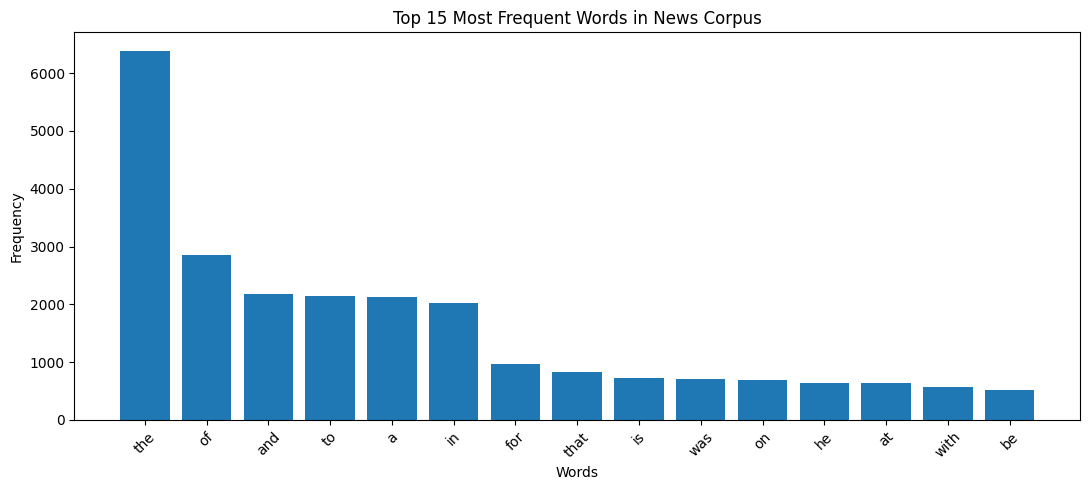


========== CONCORDANCE ANALYSIS ==========

Searching for the word 'government':
Displaying 10 of 73 matches:
ar per student . In addition , the government would pay a $1,000 `` cost of educ
s in the 1961-62 budget for direct government research in medicine . The Preside
he outcome in Laos was a coalition government susceptible of Communist dominatio
neutralized Laos . The pro-Western government , which the United States had help
e Souvanna Phouma `` neutralist '' government , never did appear to spark much f
tes would not back the pro-Western government to the hilt . If the administratio
am , Mr. Hawksley said the federal government would pay half the salary of a ful
e eligible to apply to the federal government for financial aid in purchasing eq
o the local level from the federal government . Rhode Island is going to examine
e `` great revenue '' to the local government . The council advised the governor

Searching for the word 'president':
Displaying 5 of 142 matches:
of Hays , Kan

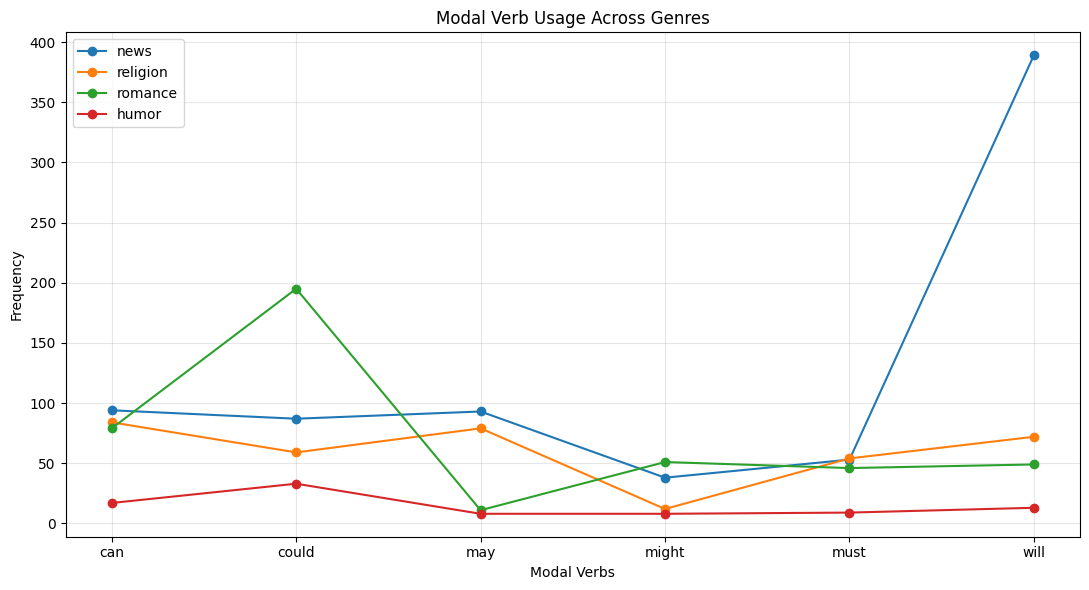


========== BIGRAM COLLOCATION ANALYSIS ==========

Top 15 Bigram Collocations:
dolce vita --> PMI Score: 13.194
notre dame --> PMI Score: 13.194
scottish rite --> PMI Score: 13.194
hong kong --> PMI Score: 12.931
anne arundel --> PMI Score: 12.709
viet nam --> PMI Score: 12.709
potato chip --> PMI Score: 12.668
assemblies god --> PMI Score: 12.031
el paso --> PMI Score: 11.931
collective bargaining --> PMI Score: 11.887
los angeles --> PMI Score: 11.709
nuclear weapons --> PMI Score: 11.446
southeast asia --> PMI Score: 11.446
wedding trip --> PMI Score: 11.346
latin america --> PMI Score: 11.330


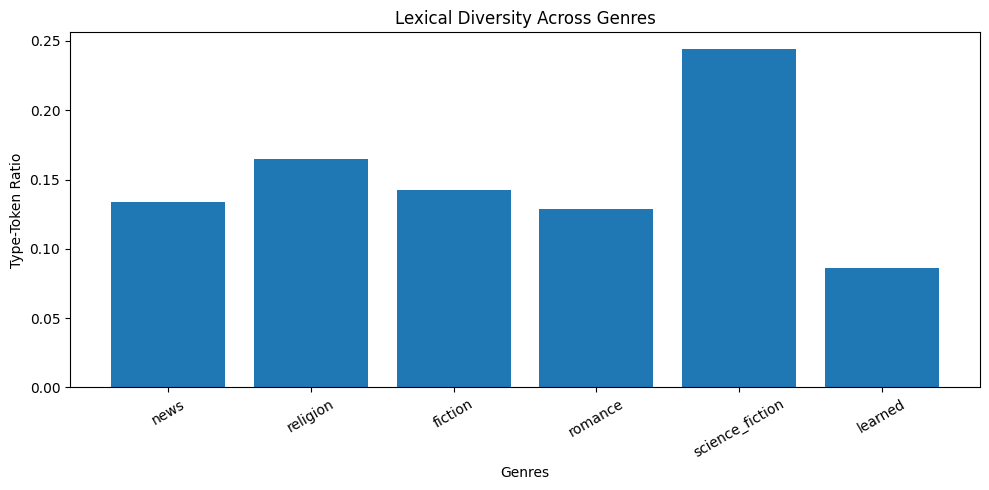

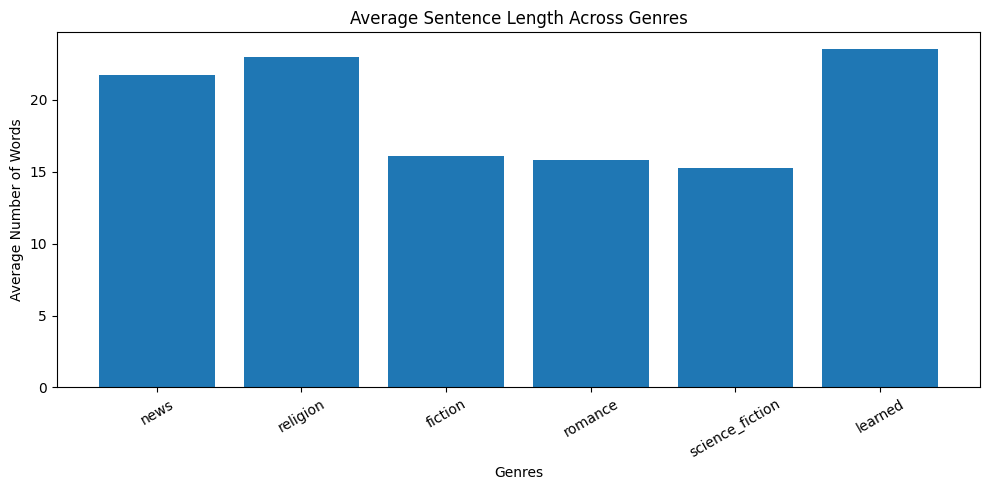


FINAL CORPUS ANALYSIS REPORT
Total Corpus Words: 1161192
Total Corpus Sentences: 57340
Total Corpus Genres: 15
News Vocabulary Size: 11151
Hapax Percentage: 48.58 %
Total Bigrams Found: 131

Analyzed Genres: ['news', 'religion', 'romance', 'humor']

CORPUS ANALYSIS COMPLETED SUCCESSFULLY!


In [ ]:
# 2.1 CORPUS ANALYSIS USING NLTK AND BROWN CORPUS

# STEP 1: IMPORT REQUIRED LIBRARIES

import nltk
import matplotlib.pyplot as plt
import pandas as pd

from nltk import FreqDist, ConditionalFreqDist, Text
from nltk.corpus import brown, stopwords

from nltk.collocations import (
    BigramCollocationFinder,
    BigramAssocMeasures
)

from collections import Counter

# STEP 2: DOWNLOAD REQUIRED DATASETS

packages = ['brown', 'stopwords']

for package in packages:
    nltk.download(package, quiet=True)

print("NLTK datasets downloaded successfully!")

# STEP 3: EXPLORE CORPUS STRUCTURE

genres = brown.categories()

print("\n========== BROWN CORPUS INFORMATION ==========")

print("Available Genres:", genres)

print("Total Words:", len(brown.words()))

print("Total Sentences:", len(brown.sents()))

print("Total Documents:", len(brown.fileids()))

# STEP 4: GENRE-WISE LEXICAL ANALYSIS

selected_genres = [
    'news',
    'religion',
    'fiction',
    'romance',
    'science_fiction',
    'learned'
]

genre_data = []

print("\n========== GENRE-WISE ANALYSIS ==========")

print(
    f"{'GENRE':<18}{'TOKENS':>10}"
    f"{'TYPES':>10}{'TTR':>10}{'AVG LENGTH':>13}"
)

for genre in selected_genres:

    words = [
        word.lower()
        for word in brown.words(categories=genre)
        if word.isalpha()
    ]

    sentences = brown.sents(categories=genre)

    total_tokens = len(words)

    unique_words = len(set(words))

    ttr = unique_words / total_tokens if total_tokens else 0

    average_length = (
        sum(len(sentence) for sentence in sentences)
        / len(sentences)
        if sentences else 0
    )

    genre_data.append({
        'Genre': genre,
        'Tokens': total_tokens,
        'Types': unique_words,
        'TTR': ttr,
        'Average Sentence Length': average_length
    })

    print(
        f"{genre:<18}{total_tokens:>10}"
        f"{unique_words:>10}{ttr:>10.3f}"
        f"{average_length:>13.2f}"
    )

genre_df = pd.DataFrame(genre_data)

# STEP 5: FREQUENCY DISTRIBUTION ANALYSIS

stop_words = set(stopwords.words('english'))

news_words = [
    word.lower()
    for word in brown.words(categories='news')
    if word.isalpha()
]

frequency = FreqDist(news_words)

print("\n========== WORD FREQUENCY ANALYSIS ==========")

print("\nTop 10 Most Frequent Words:")

print(frequency.most_common(10))

content_words = [
    (word, count)
    for word, count in frequency.most_common()
    if word not in stop_words
][:10]

print("\nTop 10 Content Words:")

print(content_words)

# Vocabulary statistics

total_vocabulary = len(frequency)

hapax_words = frequency.hapaxes()

hapax_percentage = (
    len(hapax_words) / total_vocabulary * 100
    if total_vocabulary else 0
)

print("\nUnique Vocabulary:", total_vocabulary)

print("Words Occurring Once:", len(hapax_words))

print("Hapax Percentage:", round(hapax_percentage, 2), "%")

# STEP 6: ZIPF'S LAW ANALYSIS

print("\n========== ZIPF'S LAW ==========")

for rank, (word, count) in enumerate(
    frequency.most_common(10), start=1
):

    print(
        f"Rank: {rank:<5}"
        f"Word: {word:<12}"
        f"Frequency: {count:<8}"
        f"Rank x Frequency: {rank * count}"
    )

# =====================================================
# STEP 7: WORD FREQUENCY VISUALIZATION
# =====================================================

top_words = frequency.most_common(15)

words = [word for word, count in top_words]

counts = [count for word, count in top_words]

plt.figure(figsize=(11, 5))

plt.bar(words, counts)

plt.title("Top 15 Most Frequent Words in News Corpus")

plt.xlabel("Words")

plt.ylabel("Frequency")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()

# =====================================================
# STEP 8: CONCORDANCE ANALYSIS
# =====================================================

print("\n========== CONCORDANCE ANALYSIS ==========")

news_text = Text(brown.words(categories='news'))

print("\nSearching for the word 'government':")

news_text.concordance(
    'government',
    width=80,
    lines=10
)

# Find another word
print("\nSearching for the word 'president':")

news_text.concordance(
    'president',
    width=80,
    lines=5
)

# =====================================================
# STEP 9: CONDITIONAL FREQUENCY DISTRIBUTION
# =====================================================

print("\n========== MODAL VERB ANALYSIS ==========")

selected_genres = [
    'news',
    'religion',
    'romance',
    'humor'
]

modal_verbs = [
    'can',
    'could',
    'may',
    'might',
    'must',
    'will'
]

# Count only selected modal verbs
conditional_data = []

for genre in selected_genres:

    words = [
        word.lower()
        for word in brown.words(categories=genre)
    ]

    for word in words:

        if word in modal_verbs:

            conditional_data.append((genre, word))

cfd = ConditionalFreqDist(conditional_data)

print("\nModal Verb Frequency Table:")

cfd.tabulate(
    conditions=selected_genres,
    samples=modal_verbs
)

# =====================================================
# STEP 10: MODAL VERB COMPARISON GRAPH
# =====================================================

modal_counts = {}

for genre in selected_genres:

    modal_counts[genre] = [
        cfd[genre][modal]
        for modal in modal_verbs
    ]

plt.figure(figsize=(11, 6))

for genre in selected_genres:

    plt.plot(
        modal_verbs,
        modal_counts[genre],
        marker='o',
        label=genre
    )

plt.title("Modal Verb Usage Across Genres")

plt.xlabel("Modal Verbs")

plt.ylabel("Frequency")

plt.legend()

plt.grid(alpha=0.3)

plt.tight_layout()

plt.show()

# =====================================================
# STEP 11: BIGRAM COLLOCATION ANALYSIS
# =====================================================

print("\n========== BIGRAM COLLOCATION ANALYSIS ==========")

filtered_words = [
    word.lower()
    for word in brown.words(categories='news')
    if word.isalpha() and word.lower() not in stop_words
]

bigram_finder = BigramCollocationFinder.from_words(
    filtered_words
)

# Remove rare bigrams
bigram_finder.apply_freq_filter(5)

# Calculate PMI scores
bigram_measures = BigramAssocMeasures()

top_bigrams = bigram_finder.score_ngrams(
    bigram_measures.pmi
)

print("\nTop 15 Bigram Collocations:")

for bigram, score in top_bigrams[:15]:

    print(
        f"{bigram[0]} {bigram[1]} "
        f"--> PMI Score: {score:.3f}"
    )

# =====================================================
# STEP 12: GENRE COMPARISON VISUALIZATION
# =====================================================

plt.figure(figsize=(10, 5))

plt.bar(
    genre_df['Genre'],
    genre_df['TTR']
)

plt.title("Lexical Diversity Across Genres")

plt.xlabel("Genres")

plt.ylabel("Type-Token Ratio")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

# =====================================================
# STEP 13: AVERAGE SENTENCE LENGTH COMPARISON
# =====================================================

plt.figure(figsize=(10, 5))

plt.bar(
    genre_df['Genre'],
    genre_df['Average Sentence Length']
)

plt.title("Average Sentence Length Across Genres")

plt.xlabel("Genres")

plt.ylabel("Average Number of Words")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()

# =====================================================
# STEP 14: FINAL CORPUS ANALYSIS REPORT
# =====================================================

print("\n" + "=" * 60)

print("FINAL CORPUS ANALYSIS REPORT")

print("=" * 60)

print("Total Corpus Words:", len(brown.words()))

print("Total Corpus Sentences:", len(brown.sents()))

print("Total Corpus Genres:", len(genres))

print("News Vocabulary Size:", total_vocabulary)

print("Hapax Percentage:", round(hapax_percentage, 2), "%")

print("Total Bigrams Found:", len(bigram_finder.ngram_fd))

print("\nAnalyzed Genres:", selected_genres)

print("\nCORPUS ANALYSIS COMPLETED SUCCESSFULLY!")

Parse Tree:
(S
  (NP-SBJ
    (NP (NNP Pierre) (NNP Vinken))
    (, ,)
    (ADJP (NP (CD 61) (NNS years)) (JJ old))
    (, ,))
  (VP
    (MD will)
    (VP
      (VB join)
      (NP (DT the) (NN board))
      (PP-CLR (IN as) (NP (DT a) (JJ nonexecutive) (NN director)))
      (NP-TMP (NNP Nov.) (CD 29))))
  (. .))

Leaves: ['Pierre', 'Vinken', ',', '61', 'years', 'old', ',', 'will', 'join', 'the', 'board', 'as', 'a', 'nonexecutive', 'director', 'Nov.', '29', '.']
Tree Height: 7
Number of NP Subtrees: 4

Total Tokens: 100676
Distinct POS Tags: 46
Top 10 POS Tags: [('NN', 13166), ('IN', 9857), ('NNP', 9410), ('DT', 8165), ('-NONE-', 6592), ('NNS', 6047), ('JJ', 5834), (',', 4886), ('.', 3874), ('CD', 3546)]

Top Phrase Labels: [('NP', 23724), ('VP', 14510), ('S', 8650), ('NP-SBJ', 7642), ('PP', 5159), ('SBAR', 2355), ('PP-CLR', 1226), ('PP-LOC', 1191), ('NP-SBJ-1', 1027), ('ADVP', 958)]


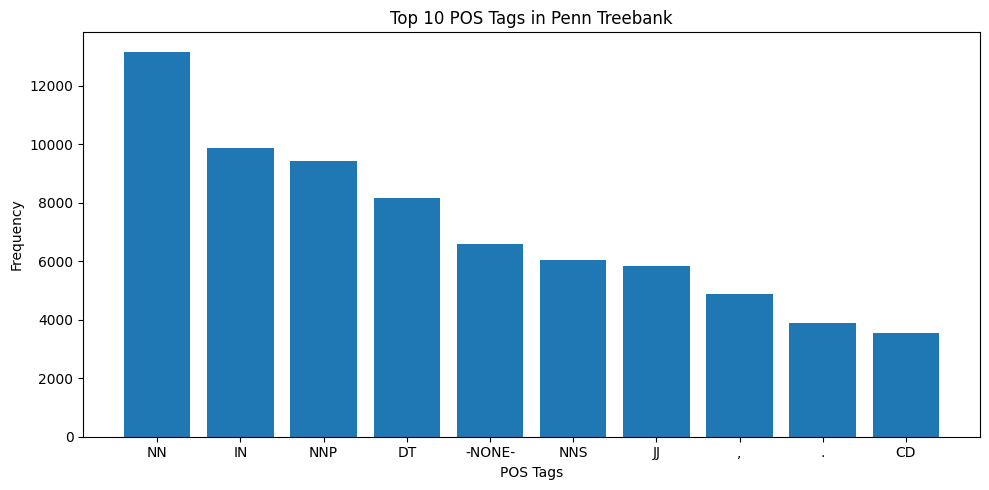


Total PCFG Productions: 3279

Top 10 Grammar Productions:
S -> NP-SBJ S|<VP-.> [0.194379]
NP-SBJ -> NP NP-SBJ|<,-ADJP> [0.00543478]
NP -> NNP NNP [0.0357143]
NNP -> 'Pierre' [0.00173913]
NNP -> 'Vinken' [0.00347826]
NP-SBJ|<,-ADJP> -> , NP-SBJ|<ADJP-,> [1.0]
, -> ',' [1.0]
NP-SBJ|<ADJP-,> -> ADJP , [1.0]
ADJP -> NP JJ [0.142857]
NP -> CD NNS [0.0162338]

Rules for Starting Symbol S:
S -> NP-SBJ S|<VP-.> [0.194379]
S -> NP-SBJ-1 S|<VP-.> [0.028103]
S -> NP-SBJ NP-PRD [0.0187354]
S -> S-TPC-1 S|<,-NP-SBJ> [0.0210773]
S -> -NONE- [0.0655738]
S -> S-TPC-2 S|<,-NP-SBJ> [0.00702576]
S -> NP-SBJ VP [0.36534]
S -> SBAR-ADV S|<,-NP-SBJ> [0.00468384]
S -> NP-SBJ-2 VP [0.0140515]
S -> NP-SBJ-1 VP [0.0210773]


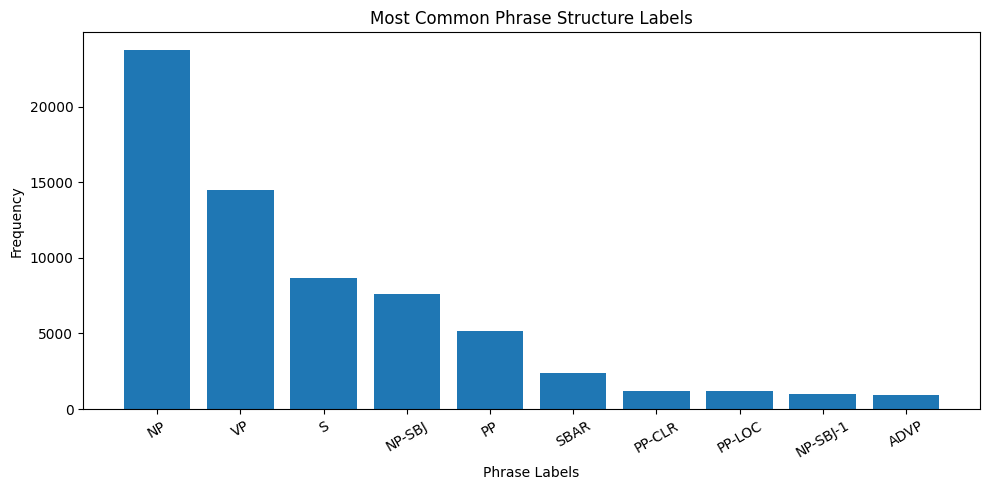


Observed Agreement: 0.7
Cohen's Kappa: 0.538

Annotation Results:
Total Sentences: 10
Agreements: 7
Disagreements: 3


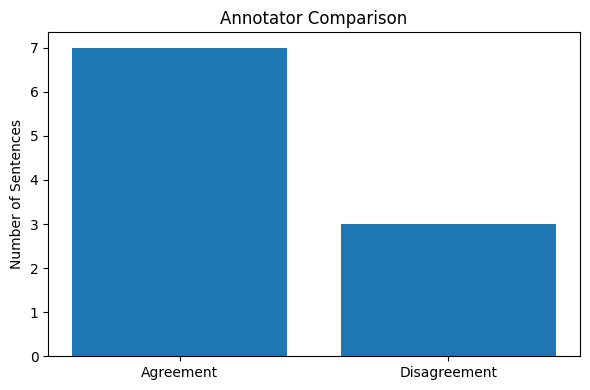


PENN TREEBANK ANALYSIS COMPLETED
Total Tokens: 100676
Unique POS Tags: 46
Total Phrase Labels: 661
PCFG Productions: 3279
Annotation Agreement: 0.7
Cohen's Kappa: 0.538


In [ ]:
# 2.2 PCFG and Treebank Analysis
import nltk
import matplotlib.pyplot as plt

from collections import Counter
from nltk import Nonterminal, induce_pcfg
from nltk.corpus import treebank
from nltk.metrics.agreement import AnnotationTask

nltk.download("treebank", quiet=True)

# 1. Inspect Penn Treebank sentence

tree = treebank.parsed_sents()[0]

print("Parse Tree:")
print(tree)

print("\nLeaves:", tree.leaves())
print("Tree Height:", tree.height())

np_count = len(
    list(tree.subtrees(lambda t: t.label() == "NP"))
)

print("Number of NP Subtrees:", np_count)

# 2. Corpus statistics

tags = Counter(tag for word, tag in treebank.tagged_words())

print("\nTotal Tokens:", sum(tags.values()))
print("Distinct POS Tags:", len(tags))
print("Top 10 POS Tags:", tags.most_common(10))

phrases = Counter(
    subtree.label()
    for sentence in treebank.parsed_sents()
    for subtree in sentence.subtrees()
    if subtree.height() > 2
)

print("\nTop Phrase Labels:", phrases.most_common(10))

# 3. POS Tag Frequency Visualization

top_tags = tags.most_common(10)

tag_names = [tag for tag, count in top_tags]
tag_counts = [count for tag, count in top_tags]

plt.figure(figsize=(10, 5))
plt.bar(tag_names, tag_counts)
plt.title("Top 10 POS Tags in Penn Treebank")
plt.xlabel("POS Tags")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# 4. Induce PCFG from Treebank

productions = []

for sentence_tree in treebank.parsed_sents()[:200]:

    sentence_tree = sentence_tree.copy(deep=True)

    sentence_tree.collapse_unary(collapsePOS=False)

    sentence_tree.chomsky_normal_form(horzMarkov=2)

    productions.extend(sentence_tree.productions())

pcfg = induce_pcfg(
    Nonterminal("S"),
    productions
)

print("\nTotal PCFG Productions:", len(pcfg.productions()))

print("\nTop 10 Grammar Productions:")

for production in pcfg.productions()[:10]:
    print(production)

print("\nRules for Starting Symbol S:")

for production in pcfg.productions(Nonterminal("S"))[:10]:
    print(production)

# 5. Phrase Distribution Visualization

top_phrases = phrases.most_common(10)

phrase_names = [label for label, count in top_phrases]
phrase_counts = [count for label, count in top_phrases]

plt.figure(figsize=(10, 5))
plt.bar(phrase_names, phrase_counts)
plt.title("Most Common Phrase Structure Labels")
plt.xlabel("Phrase Labels")
plt.ylabel("Frequency")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# 6. Annotation Agreement Analysis

annotator_a = [
    "pos", "pos", "neg", "neu", "pos",
    "neg", "neg", "neu", "pos", "neu"
]

annotator_b = [
    "pos", "pos", "neg", "pos", "pos",
    "neg", "neu", "neu", "pos", "neg"
]

annotation_data = (
    [("A", i, label) for i, label in enumerate(annotator_a)]
    +
    [("B", i, label) for i, label in enumerate(annotator_b)]
)

task = AnnotationTask(data=annotation_data)

print("\nObserved Agreement:", round(task.avg_Ao(), 3))
print("Cohen's Kappa:", round(task.kappa(), 3))

# 7. Annotation Comparison

agreement = sum(
    a == b
    for a, b in zip(annotator_a, annotator_b)
)

disagreement = len(annotator_a) - agreement

print("\nAnnotation Results:")
print("Total Sentences:", len(annotator_a))
print("Agreements:", agreement)
print("Disagreements:", disagreement)

plt.figure(figsize=(6, 4))

plt.bar(
    ["Agreement", "Disagreement"],
    [agreement, disagreement]
)

plt.title("Annotator Comparison")
plt.ylabel("Number of Sentences")
plt.tight_layout()
plt.show()

# 8. Final Summary

print("\nPENN TREEBANK ANALYSIS COMPLETED")

print("Total Tokens:", sum(tags.values()))
print("Unique POS Tags:", len(tags))
print("Total Phrase Labels:", len(phrases))
print("PCFG Productions:", len(pcfg.productions()))
print("Annotation Agreement:", round(task.avg_Ao(), 3))
print("Cohen's Kappa:", round(task.kappa(), 3))

NLTK Packages Loaded Successfully!

Dataset Information
Total Sentences: 4623
Training Sentences: 4160
Testing Sentences: 463

POS TAGGING ACCURACY
Default Tagger      : 0.2704
Unigram Tagger      : 0.9166
Bigram Tagger       : 0.9205
HMM Tagger          : 0.8877


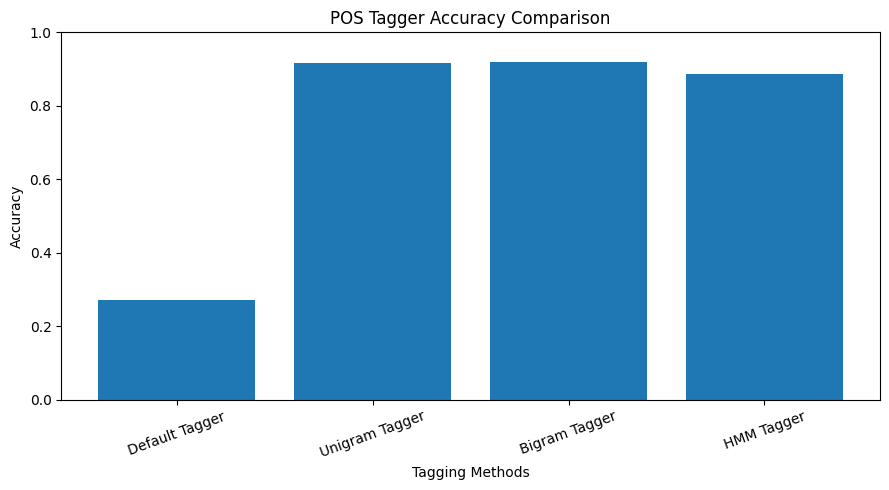


New Sentence: ['The', 'old', 'man', 'the', 'boats']

HMM Tagging:
[('The', 'DET'), ('old', 'ADJ'), ('man', 'NOUN'), ('the', 'DET'), ('boats', 'NOUN')]

Bigram Tagging:
[('The', 'DET'), ('old', 'ADJ'), ('man', 'NOUN'), ('the', 'DET'), ('boats', 'NOUN')]

Unigram Tagging:
[('The', 'DET'), ('old', 'ADJ'), ('man', 'NOUN'), ('the', 'DET'), ('boats', 'NOUN')]

TAGGING COMPARISON
Word: The       HMM: DET       Bigram: DET
Word: old       HMM: ADJ       Bigram: ADJ
Word: man       HMM: NOUN      Bigram: NOUN
Word: the       HMM: DET       Bigram: DET
Word: boats     HMM: NOUN      Bigram: NOUN

WORD SENSE DISAMBIGUATION

Sentence: I went to the bank to deposit my money
Synset: savings_bank.n.02
Meaning: a container (usually with a slot in the top) for keeping money at home

Sentence: The fisherman sat on the bank of the river
Synset: bank.n.09
Meaning: a building in which the business of banking transacted

Sentence: She visited the bank to withdraw cash
Synset: bank.n.07
Meaning: a slope in 

In [ ]:
# 2.3 POS Tagging and Word Sense Disambiguation
import nltk
import matplotlib.pyplot as plt

from nltk.corpus import brown, wordnet
from nltk.probability import LidstoneProbDist
from nltk.tag import DefaultTagger, UnigramTagger, BigramTagger, hmm
from nltk.wsd import lesk
from nltk.tokenize import word_tokenize

packages = [
    "brown",
    "universal_tagset",
    "wordnet",
    "punkt",
    "punkt_tab",
    "omw-1.4"
]

for package in packages:
    nltk.download(package, quiet=True)

print("NLTK Packages Loaded Successfully!")

# 1. Load and prepare tagged dataset

sentences = brown.tagged_sents(
    categories="news",
    tagset="universal"
)

split_index = int(len(sentences) * 0.9)

train_data = sentences[:split_index]
test_data = sentences[split_index:]

print("\nDataset Information")
print("Total Sentences:", len(sentences))
print("Training Sentences:", len(train_data))
print("Testing Sentences:", len(test_data))

# 2. Build different POS taggers

default_tagger = DefaultTagger("NOUN")

unigram_tagger = UnigramTagger(
    train_data,
    backoff=default_tagger
)

bigram_tagger = BigramTagger(
    train_data,
    backoff=unigram_tagger
)

def smoothing(fd, bins):
    return LidstoneProbDist(fd, 0.1, bins)

hmm_tagger = hmm.HiddenMarkovModelTrainer().train_supervised(
    train_data,
    estimator=smoothing
)

# 3. Evaluate all POS taggers

taggers = {
    "Default Tagger": default_tagger,
    "Unigram Tagger": unigram_tagger,
    "Bigram Tagger": bigram_tagger,
    "HMM Tagger": hmm_tagger
}

accuracy_results = {}

print("\nPOS TAGGING ACCURACY")

for name, tagger in taggers.items():

    accuracy = tagger.accuracy(test_data)

    accuracy_results[name] = accuracy

    print(f"{name:<20}: {accuracy:.4f}")

# 4. Compare tagger performance

plt.figure(figsize=(9, 5))

plt.bar(
    accuracy_results.keys(),
    accuracy_results.values()
)

plt.title("POS Tagger Accuracy Comparison")
plt.xlabel("Tagging Methods")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

# 5. Tag a new sentence

sentence = "The old man the boats".split()

print("\nNew Sentence:", sentence)

print("\nHMM Tagging:")
print(hmm_tagger.tag(sentence))

print("\nBigram Tagging:")
print(bigram_tagger.tag(sentence))

print("\nUnigram Tagging:")
print(unigram_tagger.tag(sentence))

# 6. Compare tagging results

hmm_output = hmm_tagger.tag(sentence)
bigram_output = bigram_tagger.tag(sentence)

print("\nTAGGING COMPARISON")

for word, hmm_result, bigram_result in zip(
    sentence,
    hmm_output,
    bigram_output
):

    print(
        f"Word: {word:<10}"
        f"HMM: {hmm_result[1]:<10}"
        f"Bigram: {bigram_result[1]}"
    )

# 7. Word Sense Disambiguation using Lesk Algorithm

test_sentences = [
    "I went to the bank to deposit my money",
    "The fisherman sat on the bank of the river",
    "She visited the bank to withdraw cash",
    "The boat reached the bank of the lake"
]

print("\nWORD SENSE DISAMBIGUATION")

sense_results = []

for text in test_sentences:

    tokens = word_tokenize(text)

    meaning = lesk(tokens, "bank", "n")

    if meaning:

        result = meaning.definition()
        synset = meaning.name()

    else:

        result = "No meaning found"
        synset = "Unavailable"

    sense_results.append({
        "Sentence": text,
        "Synset": synset,
        "Meaning": result
    })

    print("\nSentence:", text)
    print("Synset:", synset)
    print("Meaning:", result)

# 8. Display different meanings of the word bank

print("\nALL WORDNET MEANINGS OF BANK")

bank_synsets = wordnet.synsets("bank", pos=wordnet.NOUN)

for index, synset in enumerate(bank_synsets[:10], start=1):

    print(f"\nMeaning {index}: {synset.name()}")
    print("Definition:", synset.definition())

# 9. Final Summary

print("\nFINAL EXPERIMENT SUMMARY")

print("Total POS Taggers:", len(taggers))
print("Training Sentences:", len(train_data))
print("Testing Sentences:", len(test_data))
print("WSD Examples:", len(test_sentences))

best_tagger = max(
    accuracy_results,
    key=accuracy_results.get
)

print("Best Performing Tagger:", best_tagger)
print(
    "Highest Accuracy:",
    round(accuracy_results[best_tagger], 4)
)

print("\nPOS TAGGING AND WSD COMPLETED SUCCESSFULLY!")

TOP-DOWN PARSING
Number of parses: 2
(S
  (NP I)
  (VP
    (V saw)
    (NP (Det the) (N man) (PP (P with) (NP (Det a) (N telescope))))))
(S
  (NP I)
  (VP
    (V saw)
    (NP (Det the) (N man))
    (PP (P with) (NP (Det a) (N telescope)))))

BOTTOM-UP PARSING
Number of parses: 0

CHART PARSING
Number of parses: 2
     S                                    
  ___|___________                          
 |               VP                       
 |    ___________|________                 
 |   |       |            PP              
 |   |       |        ____|___             
 |   |       NP      |        NP          
 |   |    ___|___    |     ___|______      
 NP  V  Det      N   P   Det         N    
 |   |   |       |   |    |          |     
 I  saw the     man with  a      telescope

     S                                
  ___|_______                          
 |           VP                       
 |    _______|___                      
 |   |           NP                   
 |   |   

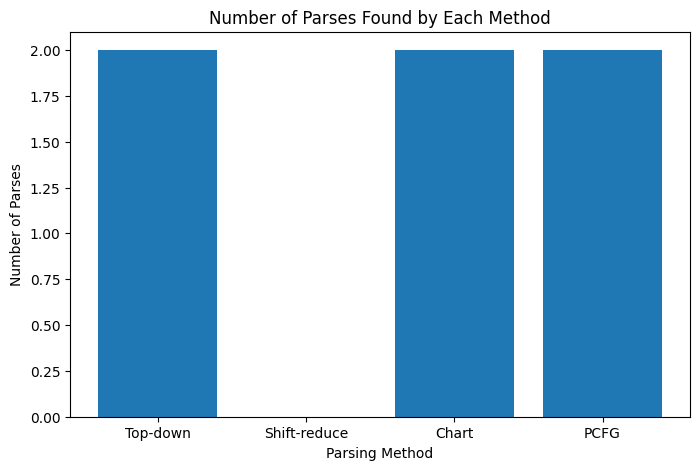


EXPERIMENT SUMMARY
Top-down parses: 2
Shift-reduce parses: 0
Chart parses: 2
PCFG parses: 2
Highest probability: 0.00115
The PCFG assigns probabilities to grammatical structures.
Viterbi selects the most probable parse.


In [ ]:
# 3.1 CFG and PCFG parsing experiment

import nltk
import matplotlib.pyplot as plt
from nltk import CFG, PCFG
from nltk.parse import RecursiveDescentParser, ShiftReduceParser, ChartParser, ViterbiParser
from nltk.parse.pchart import InsideChartParser

# 1. Define CFG with PP-attachment ambiguity
cfg = CFG.fromstring("""
S   -> NP VP
NP  -> Det N | Det N PP | 'I'
VP  -> V NP | V NP PP
PP  -> P NP
Det -> 'the' | 'a'
N   -> 'man' | 'dog' | 'telescope'
V   -> 'saw'
P   -> 'with'
""")

sent = "I saw the man with a telescope".split()

# 2. Top-down parsing
print("TOP-DOWN PARSING")
rd_parses = list(RecursiveDescentParser(cfg).parse(sent))
print("Number of parses:", len(rd_parses))

for tree in rd_parses:
    print(tree)

# 3. Bottom-up parsing
print("\nBOTTOM-UP PARSING")
sr_parses = list(ShiftReduceParser(cfg).parse(sent))
print("Number of parses:", len(sr_parses))

for tree in sr_parses:
    print(tree)

# 4. Chart parsing
print("\nCHART PARSING")
chart_parses = list(ChartParser(cfg).parse(sent))
print("Number of parses:", len(chart_parses))

for tree in chart_parses:
    tree.pretty_print()

# 5. Demonstrate left recursion limitation
print("\nLEFT RECURSION TEST")

left_rec = CFG.fromstring("""
S -> NP VP
NP -> NP PP | 'I'
VP -> 'saw'
PP -> 'with'
""")

try:
    left_parser = RecursiveDescentParser(left_rec)
    left_results = list(left_parser.parse("I saw".split()))
    print("Parses found:", len(left_results))
except (RecursionError, TimeoutError) as err:
    print("Left-recursive grammar issue:", type(err).__name__)

# 6. Define PCFG with probabilities
pcfg = PCFG.fromstring("""
S   -> NP VP        [1.0]
NP  -> Det N        [0.5]
NP  -> Det N PP     [0.2]
NP  -> 'I'          [0.3]
VP  -> V NP         [0.6]
VP  -> V NP PP      [0.4]
PP  -> P NP         [1.0]
Det -> 'the'        [0.6] | 'a' [0.4]
N   -> 'man'        [0.4] | 'dog' [0.2] | 'telescope' [0.4]
V   -> 'saw'        [1.0]
P   -> 'with'       [1.0]
""")

# 7. Viterbi parsing
print("\nVITERBI PARSING")
viterbi_parses = list(ViterbiParser(pcfg).parse(sent))

if viterbi_parses:
    best_parse = viterbi_parses[0]
    print("Most probable parse:")
    print(best_parse)
    print("Probability:", best_parse.prob())

# 8. Rank all parses by probability
print("\nALL PCFG PARSES RANKED BY PROBABILITY")

inside_parses = list(InsideChartParser(pcfg).parse(sent))
ranked_parses = sorted(inside_parses, key=lambda tree: tree.prob(), reverse=True)

for index, tree in enumerate(ranked_parses, start=1):
    print(f"\nParse {index}")
    print("Probability:", round(tree.prob(), 5))
    print(tree)

# 9. Compare parsing methods
methods = ["Top-down", "Shift-reduce", "Chart", "PCFG"]
counts = [
    len(rd_parses),
    len(sr_parses),
    len(chart_parses),
    len(inside_parses)
]

plt.figure(figsize=(8, 5))
plt.bar(methods, counts)
plt.title("Number of Parses Found by Each Method")
plt.xlabel("Parsing Method")
plt.ylabel("Number of Parses")
plt.show()

# 10. Final summary
print("\nEXPERIMENT SUMMARY")
print("Top-down parses:", len(rd_parses))
print("Shift-reduce parses:", len(sr_parses))
print("Chart parses:", len(chart_parses))
print("PCFG parses:", len(inside_parses))

if ranked_parses:
    print("Highest probability:", round(ranked_parses[0].prob(), 5))

print("The PCFG assigns probabilities to grammatical structures.")
print("Viterbi selects the most probable parse.")

JACCARD SIMILARITY
Document 0 and 1: 0.375
Document 0 and 2: 0.1

TF-IDF FEATURES
Vocabulary size: 23
TF-IDF matrix shape: (6, 23)

COSINE SIMILARITY
Manual calculation: 0.574
Using sklearn: 0.574

DOCUMENT SIMILARITY MATRIX
[[1.   0.57 0.   0.   0.   0.  ]
 [0.57 1.   0.   0.   0.   0.  ]
 [0.   0.   1.   0.   0.   0.  ]
 [0.   0.   0.   1.   0.   0.  ]
 [0.   0.   0.   0.   1.   0.14]
 [0.   0.   0.   0.   0.14 1.  ]]


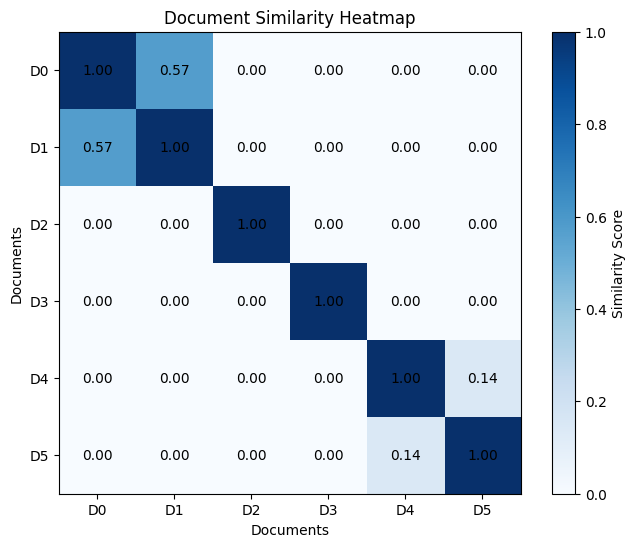


QUERY SEARCH: football match result
Document 5: Score = 0.327
The football team won the championship final
Document 4: Score = 0.327
The striker scored twice in the final match
Document 3: Score = 0.000
Shares dropped as investors sold stocks

K-MEANS CLUSTERING

Cluster 0:
- Stock markets fell sharply on Monday
- Shares dropped as investors sold stocks

Cluster 1:
- The striker scored twice in the final match
- The football team won the championship final

Cluster 2:
- The cat sat on the mat
- A cat was sitting on a mat


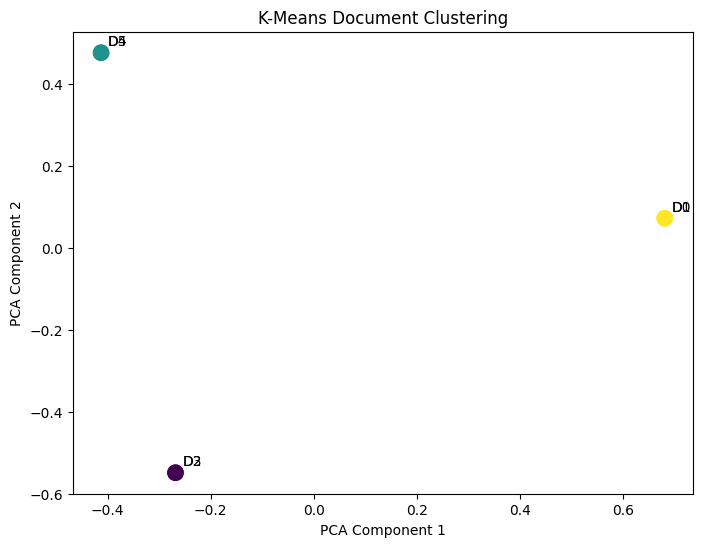

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]


SEMANTIC SIMILARITY
Dog and puppy: 0.538
Dog and law: -0.057

EXPERIMENT SUMMARY
Total documents: 6
Vocabulary size: 23
Number of clusters: 3
Top matching document: 5
Top matching similarity score: 0.327
Document similarity and clustering completed.


In [ ]:
# 3.2 document similarity and clustering experiment

import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import PCA

docs = [
    "The cat sat on the mat",
    "A cat was sitting on a mat",
    "Stock markets fell sharply on Monday",
    "Shares dropped as investors sold stocks",
    "The striker scored twice in the final match",
    "The football team won the championship final"
]

# 1. Jaccard similarity
def jaccard(a, b):
    A = set(a.lower().split())
    B = set(b.lower().split())
    return len(A & B) / len(A | B) if A | B else 0

print("JACCARD SIMILARITY")
print("Document 0 and 1:", round(jaccard(docs[0], docs[1]), 3))
print("Document 0 and 2:", round(jaccard(docs[0], docs[2]), 3))

# 2. TF-IDF vectorization
vec = TfidfVectorizer(stop_words="english")
X = vec.fit_transform(docs)
dense = X.toarray()

print("\nTF-IDF FEATURES")
print("Vocabulary size:", len(vec.get_feature_names_out()))
print("TF-IDF matrix shape:", X.shape)

# 3. Manual and sklearn cosine similarity
def cosine(u, v):
    denominator = np.linalg.norm(u) * np.linalg.norm(v)
    return float(u @ v / denominator) if denominator else 0.0

manual_score = cosine(dense[0], dense[1])
sklearn_score = cosine_similarity(X[0], X[1])[0, 0]

print("\nCOSINE SIMILARITY")
print("Manual calculation:", round(manual_score, 3))
print("Using sklearn:", round(sklearn_score, 3))

# 4. Similarity matrix
sim = cosine_similarity(X)

print("\nDOCUMENT SIMILARITY MATRIX")
np.set_printoptions(precision=2, suppress=True)
print(sim)

plt.figure(figsize=(8, 6))
plt.imshow(sim, cmap="Blues")
plt.colorbar(label="Similarity Score")
plt.xticks(range(len(docs)), [f"D{i}" for i in range(len(docs))])
plt.yticks(range(len(docs)), [f"D{i}" for i in range(len(docs))])
plt.title("Document Similarity Heatmap")
plt.xlabel("Documents")
plt.ylabel("Documents")

for i in range(len(docs)):
    for j in range(len(docs)):
        plt.text(j, i, f"{sim[i, j]:.2f}", ha="center", va="center")

plt.show()

# 5. Search query and rank documents
query = "football match result"
q = vec.transform([query])
scores = cosine_similarity(q, X)[0]
rank = scores.argsort()[::-1]

print("\nQUERY SEARCH:", query)
for i in rank[:3]:
    print(f"Document {i}: Score = {scores[i]:.3f}")
    print(docs[i])

# 6. K-Means clustering
km = KMeans(n_clusters=3, n_init=10, random_state=0)
labels = km.fit_predict(X)

print("\nK-MEANS CLUSTERING")
for c in range(3):
    cluster_docs = [docs[i] for i in range(len(docs)) if labels[i] == c]
    print(f"\nCluster {c}:")
    for document in cluster_docs:
        print("-", document)

# 7. Visualize document clusters using PCA
pca = PCA(n_components=2)
points = pca.fit_transform(dense)

plt.figure(figsize=(8, 6))
plt.scatter(points[:, 0], points[:, 1], c=labels, cmap="viridis", s=120)

for i, point in enumerate(points):
    plt.annotate(f"D{i}", (point[0], point[1]), xytext=(5, 5),
                 textcoords="offset points")

plt.title("K-Means Document Clustering")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

# 8. Optional semantic similarity using Sentence Transformers
try:
    from sentence_transformers import SentenceTransformer

    model = SentenceTransformer("all-MiniLM-L6-v2")

    examples = [
        "A dog is running in the park",
        "A puppy runs outside",
        "The parliament passed a new law"
    ]

    embeddings = model.encode(examples)

    semantic_sim = cosine_similarity(embeddings)

    print("\nSEMANTIC SIMILARITY")
    print("Dog and puppy:",
          round(semantic_sim[0, 1], 3))
    print("Dog and law:",
          round(semantic_sim[0, 2], 3))

except ImportError:
    print("\nSentence Transformers not installed.")
    print("Install using: !pip install sentence-transformers")
except Exception as e:
    print("\nOptional semantic similarity step skipped:", str(e))

# 9. Final summary
print("\nEXPERIMENT SUMMARY")
print("Total documents:", len(docs))
print("Vocabulary size:", len(vec.get_feature_names_out()))
print("Number of clusters:", len(set(labels)))
print("Top matching document:", rank[0])
print("Top matching similarity score:", round(scores[rank[0]], 3))
print("Document similarity and clustering completed.")

Iteration  1: t(casa|house) = 0.440, t(libro|book) = 0.440, t(verde|green) = 0.333
Iteration  5: t(casa|house) = 0.681, t(libro|book) = 0.681, t(verde|green) = 0.925
Iteration 10: t(casa|house) = 0.788, t(libro|book) = 0.788, t(verde|green) = 0.995
Iteration 15: t(casa|house) = 0.822, t(libro|book) = 0.822, t(verde|green) = 1.000
Iteration 20: t(casa|house) = 0.831, t(libro|book) = 0.831, t(verde|green) = 1.000

LEARNED LEXICAL TRANSLATIONS
a        -> un       Probability = 0.666
book     -> libro    Probability = 0.831
green    -> verde    Probability = 1.000
house    -> casa     Probability = 0.831
the      -> la       Probability = 0.666


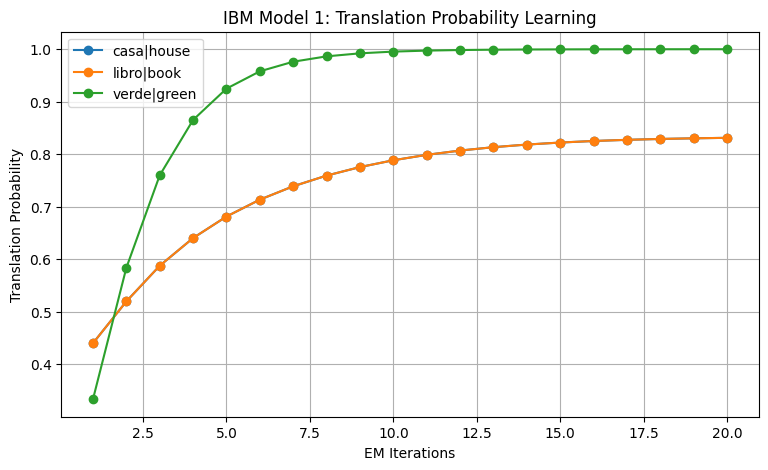


WORD ALIGNMENT

English: the house
Spanish: la casa
  la -> the (0.666)
  casa -> house (0.831)

English: the book
Spanish: el libro
  el -> the (0.333)
  libro -> book (0.831)

English: a book
Spanish: un libro
  un -> a (0.666)
  libro -> book (0.831)

English: a house
Spanish: una casa
  una -> a (0.333)
  casa -> house (0.831)

English: the green house
Spanish: la casa verde
  la -> the (0.666)
  casa -> house (0.831)
  verde -> green (1.000)

English: a green book
Spanish: un libro verde
  un -> a (0.666)
  libro -> book (0.831)
  verde -> green (1.000)

TRANSLATION RESULTS
the green book -> la verde libro
a house -> un casa
the book -> la libro
a green book -> un verde libro


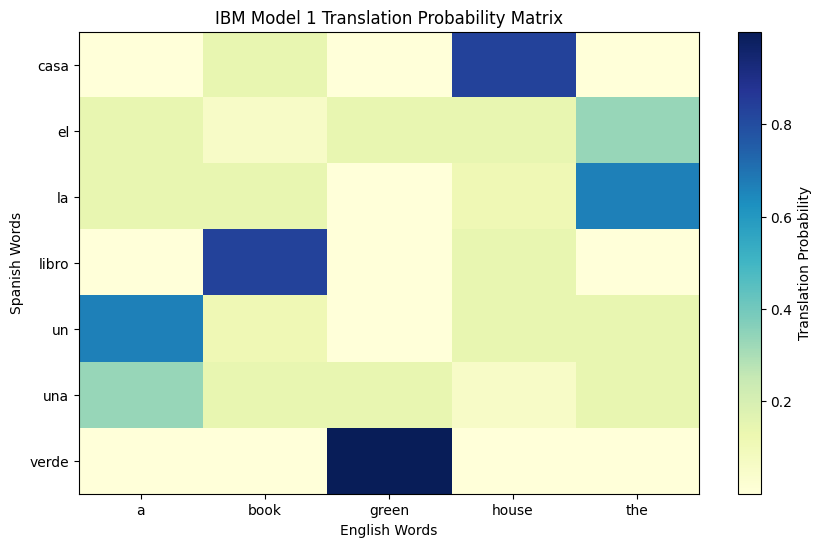


EXPERIMENT SUMMARY
English vocabulary size: 5
Spanish vocabulary size: 7
Parallel sentence pairs: 6
EM iterations completed: 20
Translation model: IBM Model 1
Learning algorithm: Expectation-Maximization (EM)
Statistical machine translation completed.


In [ ]:
# 3.3 Statistical Machine Translation experiment using IBM Model 1 and the EM algorithm

from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt

# 1. English-Spanish parallel corpus
corpus = [
    ("the house".split(), "la casa".split()),
    ("the book".split(), "el libro".split()),
    ("a book".split(), "un libro".split()),
    ("a house".split(), "una casa".split()),
    ("the green house".split(), "la casa verde".split()),
    ("a green book".split(), "un libro verde".split())
]

e_vocab = {w for e, _ in corpus for w in e}
f_vocab = {w for _, f in corpus for w in f}

# 2. Initialize translation probabilities
t = {
    (f, e): 1 / len(f_vocab)
    for f in f_vocab
    for e in e_vocab | {"NULL"}
}

# 3. IBM Model 1 using EM algorithm
history = defaultdict(list)

for iteration in range(1, 21):
    count = defaultdict(float)
    total = defaultdict(float)

    # E-step: calculate expected counts
    for e_sent, f_sent in corpus:
        e_sent = ["NULL"] + e_sent

        for f in f_sent:
            z = sum(t[(f, e)] for e in e_sent)

            for e in e_sent:
                c = t[(f, e)] / z
                count[(f, e)] += c
                total[e] += c

    # M-step: update translation probabilities
    for (f, e) in count:
        t[(f, e)] = count[(f, e)] / total[e]

    for e, f in [
        ("house", "casa"),
        ("book", "libro"),
        ("green", "verde")
    ]:
        history[f"{f}|{e}"].append(t[(f, e)])

    if iteration in (1, 5, 10, 15, 20):
        print(
            f"Iteration {iteration:2}: "
            f"t(casa|house) = {t[('casa','house')]:.3f}, "
            f"t(libro|book) = {t[('libro','book')]:.3f}, "
            f"t(verde|green) = {t[('verde','green')]:.3f}"
        )

# 4. Display best word translations
print("\nLEARNED LEXICAL TRANSLATIONS")

for e in sorted(e_vocab):
    best = max(f_vocab, key=lambda f: t.get((f, e), 0))
    print(f"{e:8} -> {best:8} Probability = {t.get((best, e), 0):.3f}")

# 5. Plot translation probability convergence
plt.figure(figsize=(9, 5))

for label, values in history.items():
    plt.plot(range(1, 21), values, marker="o", label=label)

plt.title("IBM Model 1: Translation Probability Learning")
plt.xlabel("EM Iterations")
plt.ylabel("Translation Probability")
plt.legend()
plt.grid(True)
plt.show()

# 6. Word alignment
print("\nWORD ALIGNMENT")

for e_sent, f_sent in corpus:
    e_words = ["NULL"] + e_sent
    print("\nEnglish:", " ".join(e_sent))
    print("Spanish:", " ".join(f_sent))

    for f in f_sent:
        best_e = max(e_words, key=lambda e: t.get((f, e), 0))
        print(f"  {f} -> {best_e} ({t.get((f, best_e), 0):.3f})")

# 7. Word-by-word translation decoder
def translate(sentence):
    translated = []

    for e in sentence.lower().split():
        if e in e_vocab:
            best = max(f_vocab, key=lambda f: t.get((f, e), 0))
            translated.append(best)
        else:
            translated.append("[unknown]")

    return " ".join(translated)

print("\nTRANSLATION RESULTS")

test_sentences = [
    "the green book",
    "a house",
    "the book",
    "a green book"
]

for sentence in test_sentences:
    print(f"{sentence} -> {translate(sentence)}")

# 8. Translation probability heatmap
matrix = np.array([
    [t.get((f, e), 0) for e in sorted(e_vocab)]
    for f in sorted(f_vocab)
])

plt.figure(figsize=(10, 6))
plt.imshow(matrix, cmap="YlGnBu", aspect="auto")
plt.colorbar(label="Translation Probability")
plt.xticks(range(len(e_vocab)), sorted(e_vocab))
plt.yticks(range(len(f_vocab)), sorted(f_vocab))
plt.xlabel("English Words")
plt.ylabel("Spanish Words")
plt.title("IBM Model 1 Translation Probability Matrix")
plt.show()

# 9. Final summary
print("\nEXPERIMENT SUMMARY")
print("English vocabulary size:", len(e_vocab))
print("Spanish vocabulary size:", len(f_vocab))
print("Parallel sentence pairs:", len(corpus))
print("EM iterations completed:", 20)
print("Translation model: IBM Model 1")
print("Learning algorithm: Expectation-Maximization (EM)")
print("Statistical machine translation completed.")

INVERTED INDEX
another         -> {3: 1}
audio           -> {7: 1}
bm25            -> {6: 1}
converts        -> {3: 1, 7: 1}
cosine          -> {6: 1}
decoder         -> {5: 1}
documents       -> {1: 1, 2: 1, 4: 1, 6: 1}
encoder         -> {5: 1}
engines         -> {2: 1}
evaluate        -> {8: 1}
find            -> {2: 1}
functions       -> {6: 1}
idf             -> {4: 1}
index           -> {2: 1}
information     -> {1: 1}
inverted        -> {2: 1}
language        -> {3: 1}
machine         -> {3: 1, 5: 1}
model           -> {4: 1}
networks        -> {5: 1}
neural          -> {5: 1}
one             -> {3: 1}
precision       -> {8: 1}
quality         -> {8: 1}
queries         -> {4: 1}
query           -> {1: 1}
quickly         -> {2: 1}
rank            -> {1: 1}
ranking         -> {6: 1}
recall          -> {8: 1}
recognition     -> {7: 1}
relevance       -> {1: 1}
represents      -> {4: 1}
results         -> {8: 1}
retrieval       -> {1: 1, 8: 1}
score           -> {6: 1}
search       

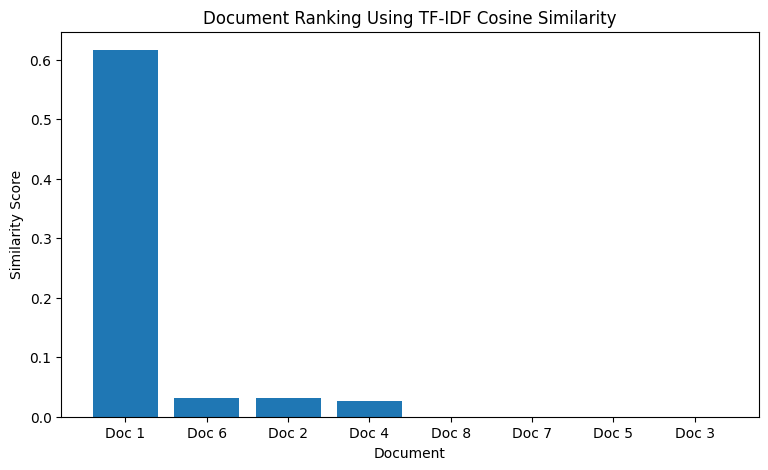

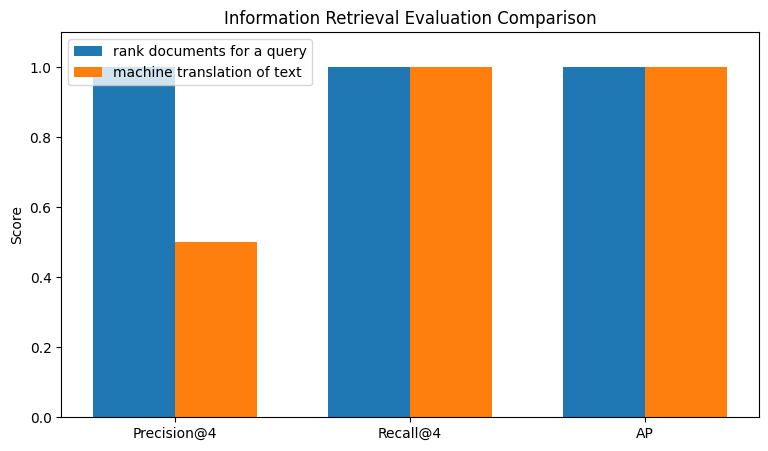


EXPERIMENT SUMMARY
Total documents: 8
Total unique terms: 47
Total queries: 2
Evaluation metric: Precision@4, Recall@4, AP and MAP
Mean Average Precision: 1.0
Information Retrieval experiment completed.


In [ ]:
# 4.1Information Retrieval: Inverted Index, Vector Space Model and Evaluation

import math
import re
import matplotlib.pyplot as plt
import numpy as np
from collections import defaultdict, Counter

# 1. Document collection
docs = {
    1: "Information retrieval systems rank documents by relevance to a query",
    2: "Search engines use an inverted index to find documents quickly",
    3: "Machine translation converts text from one language to another",
    4: "The vector space model represents documents and queries as TF-IDF vectors",
    5: "Neural machine translation uses encoder decoder networks",
    6: "Ranking functions such as BM25 and cosine similarity score documents",
    7: "Speech recognition converts spoken audio into text",
    8: "Precision and recall evaluate the quality of retrieval results"
}

# 2. Relevance judgments
queries = {
    "rank documents for a query": {1, 4, 6, 2},
    "machine translation of text": {3, 5}
}

def tokenize(text):
    return re.findall(r"[a-z0-9]+", text.lower())

stop = {
    "a", "an", "the", "to", "of", "by", "as", "for",
    "and", "into", "from", "such", "use", "uses"
}

terms = {
    d: [w for w in tokenize(text) if w not in stop]
    for d, text in docs.items()
}

# 3. Build inverted index
index = defaultdict(dict)

for d, words in terms.items():
    for word, count in Counter(words).items():
        index[word][d] = count

print("INVERTED INDEX")
for word, posting in sorted(index.items()):
    print(f"{word:15} -> {posting}")

# 4. Boolean retrieval
def boolean_and(query):
    word_sets = [
        set(index.get(w, {}))
        for w in tokenize(query)
        if w not in stop
    ]

    return set.intersection(*word_sets) if word_sets else set()

def boolean_or(query):
    word_sets = [
        set(index.get(w, {}))
        for w in tokenize(query)
        if w not in stop
    ]

    return set.union(*word_sets) if word_sets else set()

print("\nBOOLEAN RETRIEVAL")
print("AND - machine translation:", sorted(boolean_and("machine translation")))
print("OR  - machine translation:", sorted(boolean_or("machine translation")))
print("AND - rank documents:", sorted(boolean_and("rank documents")))

# 5. Calculate IDF and TF-IDF
N = len(docs)

idf = {
    word: math.log10(N / len(posting))
    for word, posting in index.items()
}

def vector(words):
    tf = Counter(words)

    return {
        word: (1 + math.log10(count)) * idf.get(word, 0)
        for word, count in tf.items()
    }

def cosine(a, b):
    dot = sum(a[w] * b.get(w, 0) for w in a)

    norm_a = math.sqrt(sum(v * v for v in a.values()))
    norm_b = math.sqrt(sum(v * v for v in b.values()))

    return dot / (norm_a * norm_b) if norm_a and norm_b else 0.0

dvec = {
    d: vector(words)
    for d, words in terms.items()
}

# 6. Search and rank documents
def search(query, k=5):
    q_words = [w for w in tokenize(query) if w not in stop]
    q_vector = vector(q_words)

    scores = [
        (cosine(q_vector, dvec[d]), d)
        for d in docs
    ]

    return sorted(scores, reverse=True)[:k]

print("\nDOCUMENT RANKING")

for query in queries:
    print("\nQuery:", query)

    for score, doc_id in search(query, len(docs)):
        if score > 0:
            print(f"Document {doc_id}: Score = {score:.3f}")
            print(docs[doc_id])

# 7. Evaluation using Precision@K, Recall@K and AP
def evaluate(query, relevant, k=4):
    results = search(query, len(docs))
    ranked = [d for score, d in results if score > 0]

    top_k = ranked[:k]

    precision = len(set(top_k) & relevant) / k
    recall = len(set(top_k) & relevant) / len(relevant)

    ap = 0.0
    relevant_found = 0

    for rank, doc_id in enumerate(ranked, start=1):
        if doc_id in relevant:
            relevant_found += 1
            ap += relevant_found / rank

    ap = ap / len(relevant)

    return ranked, precision, recall, ap

# 8. Evaluate all queries
aps = []
evaluation_results = {}

print("\nEVALUATION RESULTS")

for query, relevant in queries.items():
    ranked, precision, recall, ap = evaluate(query, relevant)

    aps.append(ap)

    evaluation_results[query] = {
        "Precision@4": precision,
        "Recall@4": recall,
        "AP": ap
    }

    print(f"\nQuery: {query}")
    print("Ranking:", ranked)
    print(f"Precision@4 = {precision:.2f}")
    print(f"Recall@4    = {recall:.2f}")
    print(f"Average Precision = {ap:.2f}")

map_score = sum(aps) / len(aps)

print("\nMEAN AVERAGE PRECISION (MAP) =", round(map_score, 3))

# 9. Visualize document ranking scores
query = "rank documents for a query"
results = search(query, len(docs))

doc_ids = [d for score, d in results]
scores = [score for score, d in results]

plt.figure(figsize=(9, 5))
plt.bar([f"Doc {d}" for d in doc_ids], scores)
plt.title("Document Ranking Using TF-IDF Cosine Similarity")
plt.xlabel("Document")
plt.ylabel("Similarity Score")
plt.show()

# 10. Compare evaluation metrics
metric_names = ["Precision@4", "Recall@4", "AP"]

x = np.arange(len(metric_names))
width = 0.35

query_names = list(evaluation_results.keys())

plt.figure(figsize=(9, 5))

for i, query_name in enumerate(query_names):
    values = [
        evaluation_results[query_name][metric]
        for metric in metric_names
    ]

    plt.bar(
        x + (i - 0.5) * width,
        values,
        width,
        label=query_name
    )

plt.xticks(x, metric_names)
plt.ylim(0, 1.1)
plt.ylabel("Score")
plt.title("Information Retrieval Evaluation Comparison")
plt.legend()
plt.show()

# 11. Final summary
print("\nEXPERIMENT SUMMARY")
print("Total documents:", len(docs))
print("Total unique terms:", len(index))
print("Total queries:", len(queries))
print("Evaluation metric: Precision@4, Recall@4, AP and MAP")
print("Mean Average Precision:", round(map_score, 3))
print("Information Retrieval experiment completed.")

POS TAGGING
[('Sundar', 'NNP'), ('Pichai', 'NNP'), ('is', 'VBZ'), ('the', 'DT'), ('chief', 'JJ'), ('executive', 'NN'), ('of', 'IN'), ('Google', 'NNP'), ('in', 'IN'), ('California', 'NNP'), ('.', '.')]
[('Satya', 'NNP'), ('Nadella', 'NNP'), ('leads', 'VBZ'), ('Microsoft', 'NNP'), ('in', 'IN'), ('Washington', 'NNP'), ('.', '.')]
[('IBM', 'NNP'), ('was', 'VBD'), ('founded', 'VBN'), ('in', 'IN'), ('New', 'NNP'), ('York', 'NNP'), ('in', 'IN'), ('1911', 'CD'), ('.', '.')]

CHUNKING RESULTS
(S
  (NP Sundar/NNP Pichai/NNP)
  (VP is/VBZ)
  (NP the/DT chief/JJ executive/NN)
  (PP of/IN (NP Google/NNP))
  (PP in/IN (NP California/NNP))
  ./.)
Noun phrases: ['Sundar Pichai', 'the chief executive', 'Google', 'California']
(S
  (NP Satya/NNP Nadella/NNP)
  (VP leads/VBZ)
  (NP Microsoft/NNP)
  (PP in/IN (NP Washington/NNP))
  ./.)
Noun phrases: ['Satya Nadella', 'Microsoft', 'Washington']
(S
  (NP IBM/NNP)
  (VP was/VBD founded/VBN)
  (PP in/IN (NP New/NNP York/NNP))
  in/IN
  1911/CD
  ./.)
Noun ph

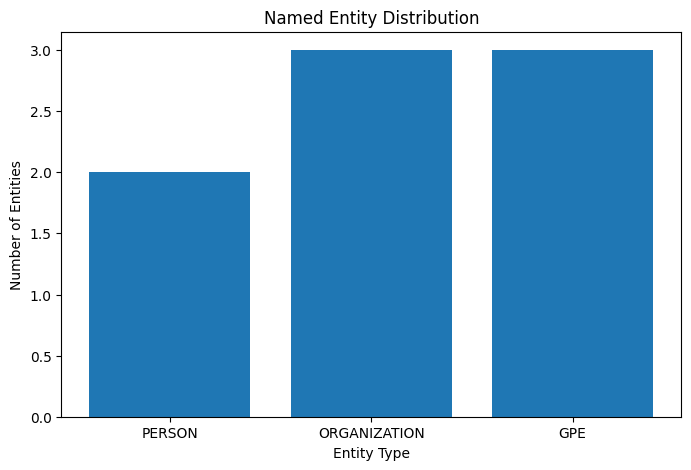

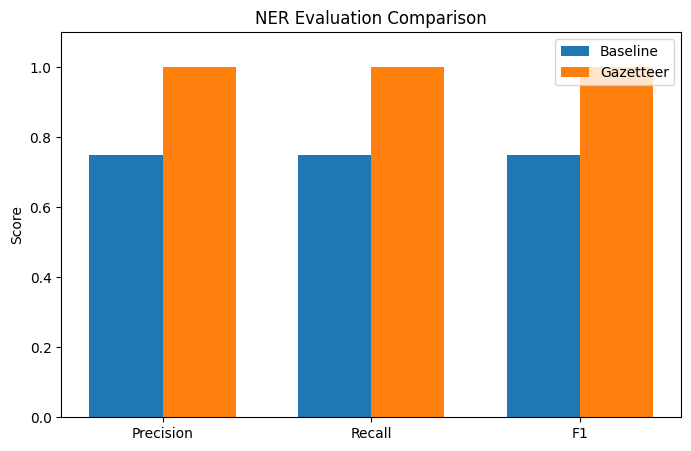


EXPERIMENT SUMMARY
Total sentences: 3
Total baseline entities: 8
Total corrected entities: 8
Total extracted relations: 2
Baseline F1: 0.75
Gazetteer F1: 1.0
NER and relation extraction completed.


In [ ]:
# 4.2 Information Extraction: Chunking, Named Entities and Relations

import nltk
import re
import matplotlib.pyplot as plt
from nltk import word_tokenize, pos_tag, RegexpParser, ne_chunk
from nltk.tree import Tree
from nltk.chunk import tree2conlltags
from collections import Counter

# 1. Download required NLTK resources
packages = [
    "punkt", "punkt_tab",
    "averaged_perceptron_tagger",
    "averaged_perceptron_tagger_eng",
    "maxent_ne_chunker",
    "maxent_ne_chunker_tab",
    "words"
]

for p in packages:
    nltk.download(p, quiet=True)

# 2. Input text
text = (
    "Sundar Pichai is the chief executive of Google in California. "
    "Satya Nadella leads Microsoft in Washington. "
    "IBM was founded in New York in 1911."
)

sentences = nltk.sent_tokenize(text)

# 3. Tokenization and POS tagging
tagged = [
    pos_tag(word_tokenize(sentence))
    for sentence in sentences
]

print("POS TAGGING")
for sentence in tagged:
    print(sentence)

# 4. Chunking using regular expressions
grammar = r"""
    NP: {<DT>?<JJ.*>*<NN.*>+}
    VP: {<VB.*>+}
    PP: {<IN><NP>}
"""

chunker = RegexpParser(grammar)

print("\nCHUNKING RESULTS")

for sentence in tagged:
    tree = chunker.parse(sentence)
    print(tree)

    noun_phrases = [
        " ".join(word for word, tag in subtree.leaves())
        for subtree in tree.subtrees(
            lambda t: t.label() == "NP"
        )
    ]

    print("Noun phrases:", noun_phrases)

# 5. IOB tagging
flat = RegexpParser(r"""
    NP: {<DT>?<JJ.*>*<NN.*>+}
    VP: {<VB.*>+}
""")

print("\nIOB TAGGING")

for sentence in tagged:
    iob_tags = tree2conlltags(flat.parse(sentence))
    print(iob_tags)

# 6. Named Entity Recognition
def entities(tagged_sentence):
    output = []
    adjacent = False

    for node in ne_chunk(tagged_sentence):
        if isinstance(node, Tree):
            entity_text = " ".join(
                word for word, tag in node.leaves()
            )

            if adjacent:
                output[-1] = (
                    output[-1][0] + " " + entity_text,
                    output[-1][1]
                )
            else:
                output.append((entity_text, node.label()))

            adjacent = True
        else:
            adjacent = False

    return output

ents = [
    entity
    for sentence in tagged
    for entity in entities(sentence)
]

print("\nBASELINE NAMED ENTITIES")
print(ents)

# 7. Gazetteer-based correction
GAZETTEER = {
    "Google": "ORGANIZATION",
    "Microsoft": "ORGANIZATION",
    "IBM": "ORGANIZATION"
}

def relabel(entity_list):
    return [
        (text, GAZETTEER.get(text, label))
        for text, label in entity_list
    ]

ents_fixed = relabel(ents)

print("\nGAZETTEER-CORRECTED ENTITIES")
print(ents_fixed)

# 8. Relation extraction
relations = []

for sentence in sentences:
    tagged_sentence = pos_tag(word_tokenize(sentence))
    extracted = relabel(entities(tagged_sentence))

    persons = [
        entity for entity, label in extracted
        if label == "PERSON"
    ]

    organizations = [
        entity for entity, label in extracted
        if label == "ORGANIZATION"
    ]

    if persons and organizations and re.search(
        r"\b(is|leads|heads)\b", sentence, re.IGNORECASE
    ):
        relations.append(
            (persons[0], "works_for", organizations[0])
        )

print("\nEXTRACTED RELATIONS")
for relation in relations:
    print(relation)

# 9. Evaluation using a gold standard
gold = {
    ("Sundar Pichai", "PERSON"),
    ("Google", "ORGANIZATION"),
    ("California", "GPE"),
    ("Satya Nadella", "PERSON"),
    ("Microsoft", "ORGANIZATION"),
    ("Washington", "GPE"),
    ("IBM", "ORGANIZATION"),
    ("New York", "GPE")
}

def prf(predicted):
    predicted = set(predicted)

    true_positive = len(gold & predicted)
    precision = true_positive / len(predicted) if predicted else 0
    recall = true_positive / len(gold) if gold else 0

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    return precision, recall, f1

baseline_scores = prf(ents)
fixed_scores = prf(ents_fixed)

print("\nEVALUATION RESULTS")

for name, scores in [
    ("Baseline", baseline_scores),
    ("Gazetteer", fixed_scores)
]:
    print(
        f"{name:12} "
        f"Precision = {scores[0]:.2f}  "
        f"Recall = {scores[1]:.2f}  "
        f"F1 = {scores[2]:.2f}"
    )

print("\nINCORRECT PREDICTIONS")
print(set(ents_fixed) - gold)

# 10. Visualize entity distribution
entity_counts = Counter(
    label for text, label in ents_fixed
)

plt.figure(figsize=(8, 5))
plt.bar(entity_counts.keys(), entity_counts.values())
plt.title("Named Entity Distribution")
plt.xlabel("Entity Type")
plt.ylabel("Number of Entities")
plt.show()

# 11. Compare evaluation metrics
metrics = ["Precision", "Recall", "F1"]

x = range(len(metrics))
width = 0.35

plt.figure(figsize=(8, 5))

plt.bar(
    [i - width / 2 for i in x],
    baseline_scores,
    width,
    label="Baseline"
)

plt.bar(
    [i + width / 2 for i in x],
    fixed_scores,
    width,
    label="Gazetteer"
)

plt.xticks(list(x), metrics)
plt.ylim(0, 1.1)
plt.ylabel("Score")
plt.title("NER Evaluation Comparison")
plt.legend()
plt.show()

# 12. Final summary
print("\nEXPERIMENT SUMMARY")
print("Total sentences:", len(sentences))
print("Total baseline entities:", len(ents))
print("Total corrected entities:", len(ents_fixed))
print("Total extracted relations:", len(relations))
print("Baseline F1:", round(baseline_scores[2], 2))
print("Gazetteer F1:", round(fixed_scores[2], 2))
print("NER and relation extraction completed.")

Question: Where was Alan Turing born?
Predicted Answer: London
Expected Answer: London
Result: CORRECT
Evidence: 
Alan Turing was born in London in 1912.
-------------------------------------------------------
Question: When did Turing propose the imitation game?
Predicted Answer: 1950
Expected Answer: 1950
Result: CORRECT
Evidence: Turing proposed the imitation game in 1950.
-------------------------------------------------------
Question: Who developed the first compiler?
Predicted Answer: Grace
Expected Answer: Grace Hopper
Result: WRONG
Evidence: Grace Hopper developed the first compiler in 1952.
-------------------------------------------------------
Question: When did Chomsky introduce generative grammar?
Predicted Answer: 1957
Expected Answer: 1957
Result: CORRECT
Evidence: Noam Chomsky introduced generative grammar in 1957.
-------------------------------------------------------
Question: Who worked at Bletchley Park?
Predicted Answer: Alan
Expected Answer: Alan Turing
Result: 

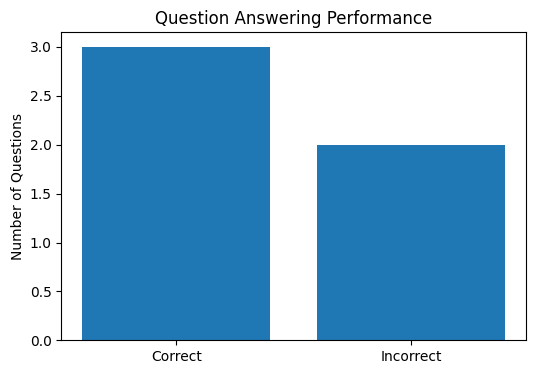

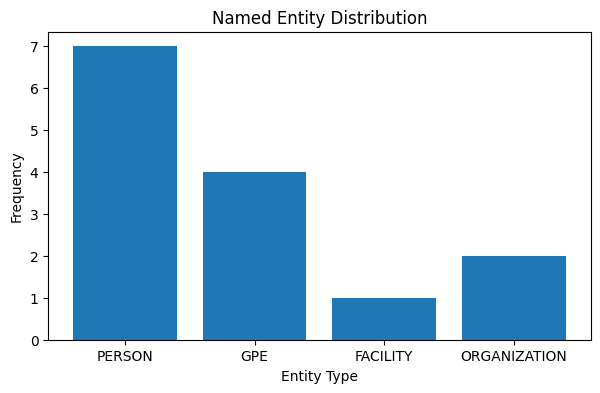


Final Summary
1. Questions classified into PERSON, LOCATION and DATE.
2. Relevant sentences retrieved using TF-IDF overlap.
3. Answers extracted using Named Entity Recognition.
4. Previous sentence context used as a fallback.
5. Final accuracy: 60.00%


In [ ]:
# 4.3 Factoid Question Answering System

import re
import nltk
import matplotlib.pyplot as plt
from collections import Counter
from nltk import word_tokenize, pos_tag, ne_chunk
from nltk.tree import Tree
from nltk.stem import PorterStemmer

# 1. Download required NLTK resources
resources = [
    "punkt", "punkt_tab",
    "averaged_perceptron_tagger",
    "averaged_perceptron_tagger_eng",
    "maxent_ne_chunker",
    "maxent_ne_chunker_tab",
    "words"
]

for resource in resources:
    nltk.download(resource, quiet=True)

# 2. Input passage
passage = """
Alan Turing was born in London in 1912.
He worked at Bletchley Park during the Second World War.
Turing proposed the imitation game in 1950.
Grace Hopper developed the first compiler in 1952.
Hopper served in the United States Navy.
Noam Chomsky introduced generative grammar in 1957.
Chomsky teaches at the Massachusetts Institute of Technology.
"""

sentences = nltk.sent_tokenize(passage)

# 3. Question classification
def answer_type(question):
    q = question.lower().strip()

    if q.startswith("who"):
        return "PERSON"
    elif q.startswith("where"):
        return "LOCATION"
    elif q.startswith("when") or "what year" in q:
        return "DATE"
    else:
        return "OTHER"

# 4. Text preprocessing and TF-IDF retrieval
stop_words = set("""
a an the of in at to was is did what who where when which by
he she it during and for from were do does
""".split())

stemmer = PorterStemmer()

def tokenize(text):
    words = re.findall(r"[a-z]+", text.lower())
    return [
        stemmer.stem(w) for w in words
        if w not in stop_words
    ]

document_tokens = [tokenize(s) for s in sentences]

df = Counter(
    word
    for doc in document_tokens
    for word in set(doc)
)

def idf(word):
    return 1 + __import__("math").log(
        len(sentences) / (1 + df[word])
    )

def retrieve(question):
    query_words = set(tokenize(question))
    scores = []

    for i, doc in enumerate(document_tokens):
        overlap = query_words & set(doc)
        score = sum(idf(w) for w in overlap)

        scores.append((score, i))

    scores.sort(reverse=True)

    return scores

# 5. Named Entity Recognition
def entities(sentence):
    tagged = pos_tag(word_tokenize(sentence))
    tree = ne_chunk(tagged)

    results = []

    for node in tree:
        if isinstance(node, Tree):
            entity_text = " ".join(
                word for word, tag in node.leaves()
            )
            results.append((entity_text, node.label()))

    return results

# 6. Answer extraction
def extract(sentence, answer_category, question):
    if answer_category == "DATE":
        dates = re.findall(
            r"\b(?:1[0-9]{3}|20[0-9]{2})\b",
            sentence
        )
        return dates[0] if dates else None

    detected = entities(sentence)
    question_words = set(tokenize(question))

    if answer_category == "PERSON":
        wanted = {"PERSON"}
    elif answer_category == "LOCATION":
        wanted = {"GPE", "GSP", "LOCATION"}
    else:
        wanted = set()

    for text, label in detected:
        entity_words = set(tokenize(text))

        if label in wanted and not entity_words & question_words:
            return text

    return None

# 7. Complete question answering system
def answer(question):
    category = answer_type(question)
    ranked_sentences = retrieve(question)

    if not ranked_sentences or ranked_sentences[0][0] <= 0:
        return None, None, 0

    best_score, best_index = ranked_sentences[0]
    evidence = sentences[best_index]

    result = extract(evidence, category, question)

    # Context-based fallback for pronouns such as He or She
    if result is None:
        for i in range(best_index - 1, -1, -1):
            result = extract(sentences[i], category, question)

            if result is not None:
                break

    return result, evidence, best_score

# 8. Test questions and evaluation
test = [
    ("Where was Alan Turing born?", "London"),
    ("When did Turing propose the imitation game?", "1950"),
    ("Who developed the first compiler?", "Grace Hopper"),
    ("When did Chomsky introduce generative grammar?", "1957"),
    ("Who worked at Bletchley Park?", "Alan Turing")
]

correct = 0
answered = 0
results = []

def normalize(text):
    return re.sub(r"[^a-z0-9]", "", text.lower()) if text else ""

for question, gold in test:
    prediction, evidence, score = answer(question)

    is_correct = (
        prediction is not None
        and normalize(prediction) == normalize(gold)
    )

    correct += is_correct
    answered += prediction is not None

    results.append({
        "question": question,
        "prediction": prediction,
        "correct": is_correct,
        "score": score
    })

    print(f"Question: {question}")
    print(f"Predicted Answer: {prediction}")
    print(f"Expected Answer: {gold}")
    print(f"Result: {'CORRECT' if is_correct else 'WRONG'}")
    print(f"Evidence: {evidence}")
    print("-" * 55)

accuracy = (correct / len(test)) * 100
coverage = (answered / len(test)) * 100

print("\nEvaluation Summary")
print("Correct Answers:", correct)
print("Total Questions:", len(test))
print(f"Accuracy: {accuracy:.2f}%")
print(f"Answer Coverage: {coverage:.2f}%")

# 9. Display named entities in the passage
print("\nNamed Entities Found:")

all_entities = []

for sentence in sentences:
    for entity, label in entities(sentence):
        all_entities.append((entity, label))
        print(f"{entity}: {label}")

# 10. Visualize question answering performance
labels = ["Correct", "Incorrect"]
values = [correct, len(test) - correct]

plt.figure(figsize=(6, 4))
plt.bar(labels, values)
plt.title("Question Answering Performance")
plt.ylabel("Number of Questions")
plt.show()

# 11. Visualize entity distribution
entity_counts = Counter(label for entity, label in all_entities)

plt.figure(figsize=(7, 4))
plt.bar(entity_counts.keys(), entity_counts.values())
plt.title("Named Entity Distribution")
plt.xlabel("Entity Type")
plt.ylabel("Frequency")
plt.show()

# 12. Final summary
print("\nFinal Summary")
print("1. Questions classified into PERSON, LOCATION and DATE.")
print("2. Relevant sentences retrieved using TF-IDF overlap.")
print("3. Answers extracted using Named Entity Recognition.")
print("4. Previous sentence context used as a fallback.")
print(f"5. Final accuracy: {accuracy:.2f}%")

STUDENT PERFORMANCE FACTS
latest: 88
mean: 74.8
best: 88
lowest: 62
trend: 26
above_avg_weeks: 5
weeks: 5
percentage: 88.0
trend_type: improving
band: distinction
consistency: variable

FORMAL REPORT
This report summarises Asha's progress in Natural Language Processing. The latest assessment score of 88 places the student in the distinction band. The average score across all assessments is 74.80. Overall performance is improving, with a change of +26 marks. The student exceeded the class average in 5 of 5 weeks. The highest score achieved was 88. The student's performance has been variable.

AGGREGATED REPORT
This report summarises Asha's progress in Natural Language Processing. The latest assessment score of 88 places the student in the distinction band. The average score across all assessments is 74.80. Overall performance is improving, with a change of +26 marks. The student exceeded the class average in 5 of 5 weeks. The highest score achieved was 88, and the student's performance 

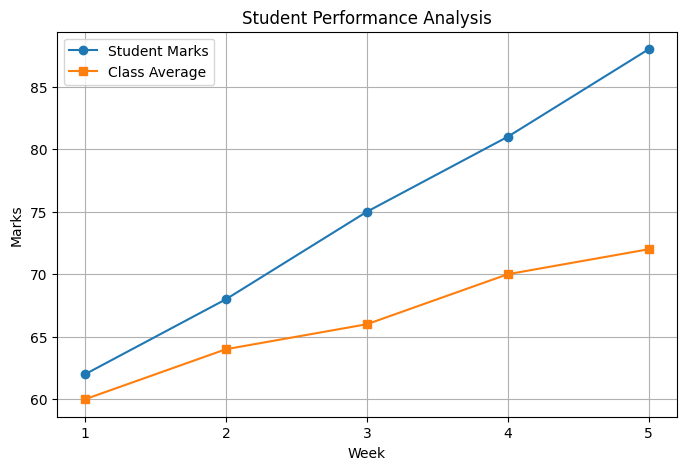

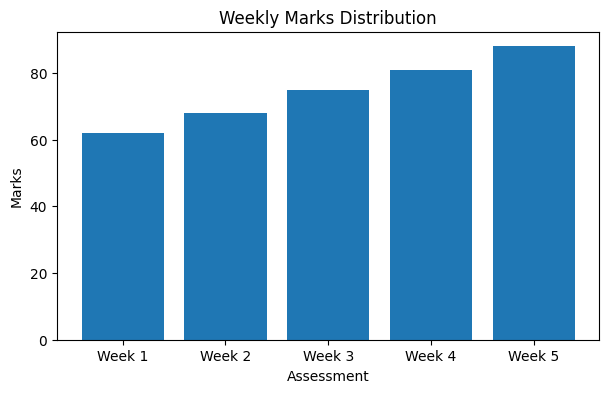


FINAL SUMMARY
Student: Asha
Latest Marks: 88
Average Marks: 74.8
Performance: distinction
Trend: improving
Class Average Comparison: 5/5 weeks


In [ ]:
# 5.1 Data-to-Text Report Generation with Style Control

import statistics
import matplotlib.pyplot as plt

# 1. Input data
record = {
    "name": "Asha",
    "course": "Natural Language Processing",
    "marks": [62, 68, 75, 81, 88],
    "max": 100,
    "class_avg": [60, 64, 66, 70, 72]
}

# 2. Content determination
def determine_content(r):
    marks = r["marks"]
    avg = r["class_avg"]

    facts = {
        "latest": marks[-1],
        "mean": statistics.mean(marks),
        "best": max(marks),
        "lowest": min(marks),
        "trend": marks[-1] - marks[0],
        "above_avg_weeks": sum(a > b for a, b in zip(marks, avg)),
        "weeks": len(marks),
        "percentage": (marks[-1] / r["max"]) * 100
    }

    facts["trend_type"] = (
        "improving" if facts["trend"] > 5
        else "declining" if facts["trend"] < -5
        else "stable"
    )

    facts["band"] = (
        "distinction" if facts["latest"] >= 85
        else "merit" if facts["latest"] >= 70
        else "pass"
    )

    facts["consistency"] = (
        "consistent" if max(marks) - min(marks) <= 20
        else "variable"
    )

    return facts

# 3. Document planning
def plan(facts):
    messages = [
        ("intro",),
        ("performance", facts["band"], facts["latest"]),
        ("average", facts["mean"]),
        ("trend", facts["trend_type"], facts["trend"]),
        ("comparison", facts["above_avg_weeks"], facts["weeks"]),
        ("best", facts["best"]),
        ("consistency", facts["consistency"])
    ]

    return messages

# 4. Surface realization
TEMPLATES = {
    "formal": {
        "intro": "This report summarises {name}'s progress in {course}.",
        "performance": "The latest assessment score of {val} places the student in the {band} band.",
        "average": "The average score across all assessments is {mean:.2f}.",
        "trend": "Overall performance is {ttype}, with a change of {delta:+d} marks.",
        "comparison": "The student exceeded the class average in {k} of {n} weeks.",
        "best": "The highest score achieved was {best}.",
        "consistency": "The student's performance has been {consistency}."
    },

    "friendly": {
        "intro": "Here is how {name} is getting on in {course}.",
        "performance": "Latest score: {val}. That's a great {band}!",
        "average": "The average score is {mean:.2f}.",
        "trend": "The performance is {ttype} ({delta:+d} marks since week one).",
        "comparison": "{name} beat the class average in {k} out of {n} weeks.",
        "best": "The best score so far is {best}.",
        "consistency": "Performance has been {consistency}."
    }
}

def realise(messages, r, style):
    template = TEMPLATES[style]
    facts = determine_content(r)
    output = []

    for message in messages:
        key = message[0]

        if key == "intro":
            sentence = template[key].format(
                name=r["name"], course=r["course"]
            )

        elif key == "performance":
            sentence = template[key].format(
                band=message[1], val=message[2]
            )

        elif key == "average":
            sentence = template[key].format(mean=message[1])

        elif key == "trend":
            sentence = template[key].format(
                ttype=message[1], delta=message[2]
            )

        elif key == "comparison":
            sentence = template[key].format(
                name=r["name"], k=message[1], n=message[2]
            )

        elif key == "best":
            sentence = template[key].format(best=message[1])

        elif key == "consistency":
            sentence = template[key].format(consistency=message[1])

        output.append(sentence)

    return output

# 5. Sentence aggregation
def aggregate(sentences):
    if len(sentences) < 2:
        return sentences

    return sentences[:-2] + [
        sentences[-2].rstrip(".!") + ", and " +
        sentences[-1][0].lower() + sentences[-1][1:]
    ]

# 6. Generate reports
facts = determine_content(record)
messages = plan(facts)

print("STUDENT PERFORMANCE FACTS")
for key, value in facts.items():
    print(f"{key}: {value}")

for style in ("formal", "friendly"):
    report = realise(messages, record, style)

    print(f"\n{style.upper()} REPORT")
    print(" ".join(report))

    print("\nAGGREGATED REPORT")
    print(" ".join(aggregate(report)))

# 7. Test with additional student records
students = [
    {
        "name": "Ravi",
        "course": "Natural Language Processing",
        "marks": [80, 76, 70, 66, 61],
        "max": 100,
        "class_avg": [60, 64, 66, 70, 72]
    },
    {
        "name": "Neha",
        "course": "Natural Language Processing",
        "marks": [55, 60, 65, 70, 75],
        "max": 100,
        "class_avg": [60, 64, 66, 70, 72]
    }
]

print("\nADDITIONAL STUDENT REPORTS")

for student in students:
    report = realise(
        plan(determine_content(student)),
        student,
        "formal"
    )
    print("\n", " ".join(report))

# 8. Performance visualization
weeks = range(1, len(record["marks"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(weeks, record["marks"], marker="o", label="Student Marks")
plt.plot(weeks, record["class_avg"], marker="s", label="Class Average")

plt.title("Student Performance Analysis")
plt.xlabel("Week")
plt.ylabel("Marks")
plt.xticks(list(weeks))
plt.legend()
plt.grid(True)
plt.show()

# 9. Marks distribution
plt.figure(figsize=(7, 4))
plt.bar(
    [f"Week {i}" for i in weeks],
    record["marks"]
)

plt.title("Weekly Marks Distribution")
plt.xlabel("Assessment")
plt.ylabel("Marks")
plt.show()

# 10. Final summary
print("\nFINAL SUMMARY")
print("Student:", record["name"])
print("Latest Marks:", facts["latest"])
print("Average Marks:", round(facts["mean"], 2))
print("Performance:", facts["band"])
print("Trend:", facts["trend_type"])
print("Class Average Comparison:",
      f"{facts['above_avg_weeks']}/{facts['weeks']} weeks")

DOCUMENT-LEVEL SENTIMENT ANALYSIS
VADER Accuracy: 0.657

Classification Report:
              precision    recall  f1-score   support

         neg      0.728     0.421     0.534       140
         pos      0.630     0.863     0.728       160

    accuracy                          0.657       300
   macro avg      0.679     0.642     0.631       300
weighted avg      0.676     0.657     0.638       300



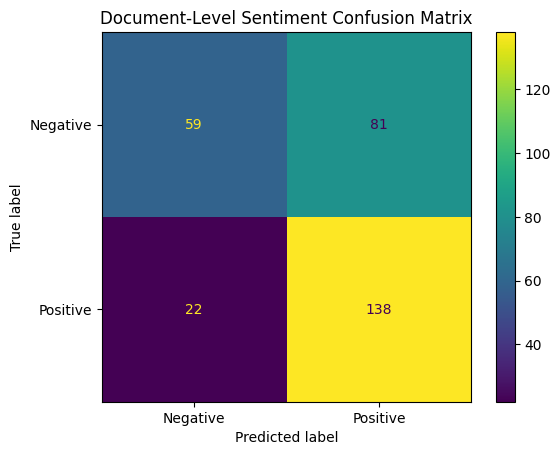


SENTENCE-LEVEL SENTIMENT ANALYSIS
+0.440 | Positive | The plot was good.
-0.341 | Negative | The plot was not good.
+0.540 | Positive | The plot was extremely good!
-0.494 | Negative | The plot was good, but the ending was terrible.
+0.635 | Positive | The movie was absolutely fantastic!
-0.494 | Negative | The acting was disappointing.

ASPECT-BASED OPINION SUMMARY
design     +0.62  Positive
battery    +0.57  Positive
screen     +0.44  Positive
price      +0.00  Neutral
camera     -0.65  Negative

OVERALL OPINION
Users like: battery, screen, design
Users complain about: camera
Neutral aspects: price


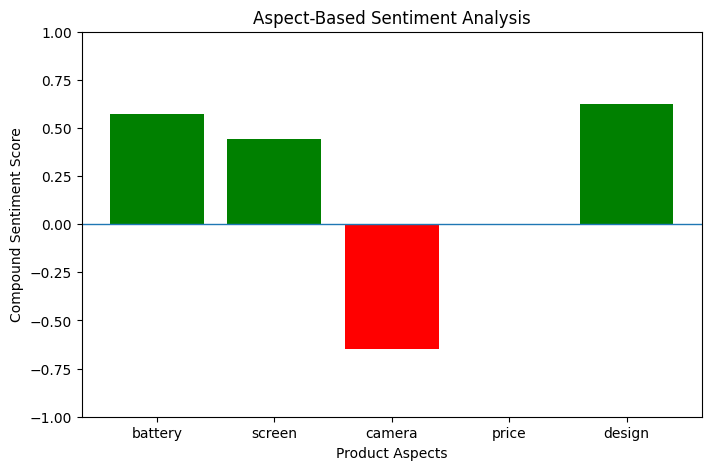

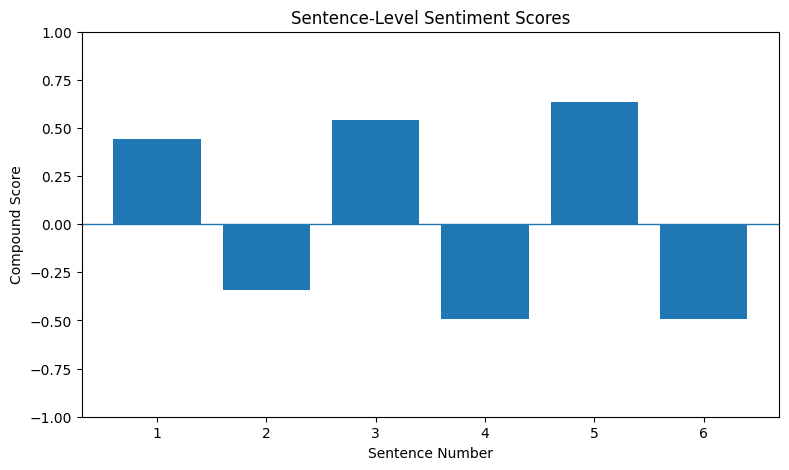


FINAL SUMMARY
Document-level accuracy: 0.657
Documents tested: 300
Positive aspects: 3
Negative aspects: 1
Neutral aspects: 1
Sentiment analysis completed successfully.


In [ ]:
# 5.2 Sentiment Analysis: Document, Sentence and Feature Levels

import random
import re
import nltk
import matplotlib.pyplot as plt
from collections import Counter
from nltk.corpus import movie_reviews
from nltk.sentiment.vader import SentimentIntensityAnalyzer
from nltk.tokenize import sent_tokenize
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. Download required resources
resources = [
    "movie_reviews",
    "vader_lexicon",
    "punkt",
    "punkt_tab"
]

for resource in resources:
    nltk.download(resource, quiet=True)

sia = SentimentIntensityAnalyzer()

# 2. Document-level sentiment analysis
random.seed(1)

ids = random.sample(movie_reviews.fileids(), 300)

gold = [
    movie_reviews.categories(f)[0]
    for f in ids
]

pred = [
    "pos" if sia.polarity_scores(
        movie_reviews.raw(f)
    )["compound"] >= 0 else "neg"
    for f in ids
]

accuracy = accuracy_score(gold, pred)

print("DOCUMENT-LEVEL SENTIMENT ANALYSIS")
print(f"VADER Accuracy: {accuracy:.3f}")
print("\nClassification Report:")
print(classification_report(gold, pred, digits=3))

# 3. Confusion matrix
cm = confusion_matrix(gold, pred, labels=["neg", "pos"])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

display.plot()
plt.title("Document-Level Sentiment Confusion Matrix")
plt.show()

# 4. Sentence-level sentiment analysis
sentences = [
    "The plot was good.",
    "The plot was not good.",
    "The plot was extremely good!",
    "The plot was good, but the ending was terrible.",
    "The movie was absolutely fantastic!",
    "The acting was disappointing."
]

print("\nSENTENCE-LEVEL SENTIMENT ANALYSIS")

sentence_scores = []

for sentence in sentences:
    score = sia.polarity_scores(sentence)["compound"]

    label = (
        "Positive" if score >= 0.05
        else "Negative" if score <= -0.05
        else "Neutral"
    )

    sentence_scores.append(score)

    print(f"{score:+.3f} | {label:8} | {sentence}")

# 5. Aspect-based sentiment analysis
review = (
    "The battery life is excellent and lasts two days. "
    "The screen is bright and sharp. "
    "However the camera is disappointing in low light. "
    "The price is too high. "
    "Overall the phone has a great design."
)

aspects = {
    "battery": ["battery"],
    "screen": ["screen", "display"],
    "camera": ["camera"],
    "price": ["price", "cost"],
    "design": ["design"]
}

summary = {}

for sentence in sent_tokenize(review):
    for aspect, keywords in aspects.items():
        if any(
            re.search(rf"\b{re.escape(word)}\b",
                      sentence.lower())
            for word in keywords
        ):
            score = sia.polarity_scores(sentence)["compound"]

            if aspect not in summary:
                summary[aspect] = []

            summary[aspect].append(score)

# Calculate average sentiment for each aspect
summary = {
    aspect: sum(scores) / len(scores)
    for aspect, scores in summary.items()
}

print("\nASPECT-BASED OPINION SUMMARY")

for aspect, score in sorted(
    summary.items(),
    key=lambda x: x[1],
    reverse=True
):
    label = (
        "Positive" if score > 0.05
        else "Negative" if score < -0.05
        else "Neutral"
    )

    print(f"{aspect:10} {score:+.2f}  {label}")

# 6. Overall opinion summary
positive = [
    aspect for aspect, score in summary.items()
    if score > 0.05
]

negative = [
    aspect for aspect, score in summary.items()
    if score < -0.05
]

neutral = [
    aspect for aspect, score in summary.items()
    if -0.05 <= score <= 0.05
]

print("\nOVERALL OPINION")

print(
    "Users like: " +
    (", ".join(positive) if positive else "None")
)

print(
    "Users complain about: " +
    (", ".join(negative) if negative else "None")
)

print(
    "Neutral aspects: " +
    (", ".join(neutral) if neutral else "None")
)

# 7. Aspect sentiment visualization
plt.figure(figsize=(8, 5))

colors = [
    "green" if score > 0.05
    else "red" if score < -0.05
    else "gray"
    for score in summary.values()
]

plt.bar(summary.keys(), summary.values(), color=colors)
plt.axhline(0, linewidth=1)
plt.title("Aspect-Based Sentiment Analysis")
plt.xlabel("Product Aspects")
plt.ylabel("Compound Sentiment Score")
plt.ylim(-1, 1)
plt.show()

# 8. Sentence sentiment visualization
plt.figure(figsize=(9, 5))

plt.bar(
    range(1, len(sentence_scores) + 1),
    sentence_scores
)

plt.axhline(0, linewidth=1)
plt.title("Sentence-Level Sentiment Scores")
plt.xlabel("Sentence Number")
plt.ylabel("Compound Score")
plt.ylim(-1, 1)
plt.show()

# 9. Final evaluation summary
print("\nFINAL SUMMARY")
print(f"Document-level accuracy: {accuracy:.3f}")
print("Documents tested:", len(ids))
print("Positive aspects:", len(positive))
print("Negative aspects:", len(negative))
print("Neutral aspects:", len(neutral))
print("Sentiment analysis completed successfully.")

STRUCTURED CLINICAL INFORMATION

N1
symptom: cough, fever
Absent symptom: chest pain, shortness of breath
drug: amoxicillin

N2
symptom: headache, nausea
Absent symptom: chest pain, fever
condition: diabetes
drug: metformin

N3
symptom: chest pain
Absent symptom: cough
condition: hypertension
drug: amlodipine, aspirin

EVALUATION RESULTS
True Positives: 16
False Positives: 0
False Negatives: 0
Precision: 1.00
Recall: 1.00
F1 Score: 1.00

GENERATED CLINICAL REPORTS

N1: Presenting symptoms: cough, fever. Negative findings: chest pain, shortness of breath. Mentioned medications: amoxicillin.

N2: Presenting symptoms: headache, nausea. Negative findings: chest pain, fever. Known conditions: diabetes. Mentioned medications: metformin.

N3: Presenting symptoms: chest pain. Negative findings: cough. Known conditions: hypertension. Mentioned medications: amlodipine, aspirin.


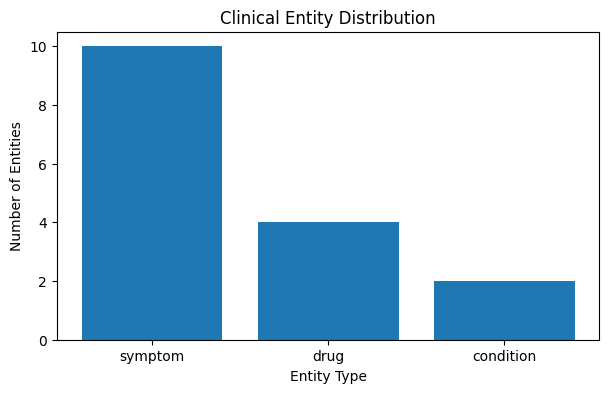

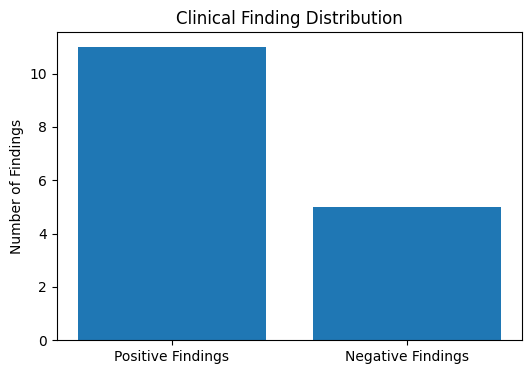


FINAL SUMMARY
Total patient notes: 3
Entity types: 3
Total extracted entities: 16
Precision: 1.00
Recall: 1.00
F1 Score: 1.00
Clinical NLP pipeline completed.


In [ ]:
# 5.3 Clinical Text Mining: Entity Extraction, Negation Detection and Summary Generation

import re
import matplotlib.pyplot as plt
from collections import defaultdict

# 1. Synthetic clinical notes
notes = {
    "N1": "Patient complains of fever and dry cough for three days. Denies chest pain. No shortness of breath. Started on amoxicillin.",
    "N2": "Reports headache and nausea. Chest pain absent. History of diabetes. Continue metformin. No fever.",
    "N3": "Presents with chest pain radiating to left arm. No cough. Hypertension noted; prescribed amlodipine and aspirin."
}

# 2. Gold annotations for evaluation
gold = {
    "N1": {
        ("fever", False), ("cough", False),
        ("chest pain", True), ("shortness of breath", True),
        ("amoxicillin", False)
    },
    "N2": {
        ("headache", False), ("nausea", False),
        ("chest pain", True), ("diabetes", False),
        ("metformin", False), ("fever", True)
    },
    "N3": {
        ("chest pain", False), ("cough", True),
        ("hypertension", False), ("amlodipine", False),
        ("aspirin", False)
    }
}

# 3. Medical entity lexicons
LEX = {
    "symptom": [
        "shortness of breath", "chest pain",
        "fever", "cough", "headache", "nausea"
    ],
    "condition": ["diabetes", "hypertension"],
    "drug": [
        "amoxicillin", "metformin",
        "amlodipine", "aspirin"
    ]
}

# 4. Negation triggers
PRE_NEG = [
    r"\bno\b",
    r"\bdenies\b",
    r"\bwithout\b",
    r"\bnegative for\b",
    r"\bnot\b"
]

POST_NEG = [
    r"\babsent\b",
    r"\bnot present\b",
    r"\bruled out\b"
]

# 5. Sentence segmentation
def sentences(text):
    return [
        s.strip()
        for s in re.split(r"(?<=[.;!?])\s+", text)
        if s.strip()
    ]

# 6. Negation detection
def is_negated(sentence, start, end):
    before = sentence[:start]
    after = sentence[end:]

    previous_words = before.split()[-4:]
    next_words = after.split()[:3]

    window_before = " ".join(previous_words)
    window_after = " ".join(next_words)

    pre = any(
        re.search(pattern, window_before)
        for pattern in PRE_NEG
    )

    post = any(
        re.search(pattern, window_after)
        for pattern in POST_NEG
    )

    return pre or post

# 7. Medical entity extraction
def extract(note):
    found = []

    for sentence in sentences(note):
        low = sentence.lower()

        for entity_type, terms in LEX.items():
            for term in terms:
                pattern = rf"\b{re.escape(term)}\b"

                for match in re.finditer(pattern, low):
                    negated = is_negated(
                        low,
                        match.start(),
                        match.end()
                    )

                    found.append({
                        "entity": term,
                        "type": entity_type,
                        "negated": negated,
                        "sentence": sentence
                    })

    return found

# 8. Structured patient summaries
print("STRUCTURED CLINICAL INFORMATION")

for patient, note in notes.items():
    results = extract(note)
    grouped = defaultdict(list)

    for item in results:
        category = (
            "Absent " if item["negated"] else ""
        ) + item["type"]

        grouped[category].append(item["entity"])

    print(f"\n{patient}")

    for category, entities in grouped.items():
        print(f"{category}: {', '.join(sorted(set(entities)))}")

# 9. Entity and negation evaluation
tp = fp = fn = 0

for patient, note in notes.items():
    predicted = {
        (item["entity"], item["negated"])
        for item in extract(note)
    }

    actual = gold[patient]

    tp += len(predicted & actual)
    fp += len(predicted - actual)
    fn += len(actual - predicted)

precision = tp / (tp + fp) if tp + fp else 0
recall = tp / (tp + fn) if tp + fn else 0

f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall else 0
)

print("\nEVALUATION RESULTS")
print("True Positives:", tp)
print("False Positives:", fp)
print("False Negatives:", fn)
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")

# 10. Natural language clinical summary
def summarise(patient):
    results = extract(notes[patient])

    symptoms = sorted({
        x["entity"] for x in results
        if x["type"] == "symptom" and not x["negated"]
    })

    negative = sorted({
        x["entity"] for x in results
        if x["negated"]
    })

    drugs = sorted({
        x["entity"] for x in results
        if x["type"] == "drug"
    })

    conditions = sorted({
        x["entity"] for x in results
        if x["type"] == "condition"
    })

    report = (
        f"{patient}: Presenting symptoms: "
        f"{', '.join(symptoms) or 'none recorded'}."
    )

    if negative:
        report += (
            f" Negative findings: {', '.join(negative)}."
        )

    if conditions:
        report += (
            f" Known conditions: {', '.join(conditions)}."
        )

    if drugs:
        report += (
            f" Mentioned medications: {', '.join(drugs)}."
        )

    return report

print("\nGENERATED CLINICAL REPORTS")

for patient in notes:
    print("\n" + summarise(patient))

# 11. Entity distribution visualization
entity_counts = Counter(
    item["type"]
    for note in notes.values()
    for item in extract(note)
)

plt.figure(figsize=(7, 4))
plt.bar(entity_counts.keys(), entity_counts.values())
plt.title("Clinical Entity Distribution")
plt.xlabel("Entity Type")
plt.ylabel("Number of Entities")
plt.show()

# 12. Positive and negative finding visualization
positive_count = 0
negative_count = 0

for note in notes.values():
    for item in extract(note):
        if item["negated"]:
            negative_count += 1
        else:
            positive_count += 1

plt.figure(figsize=(6, 4))
plt.bar(
    ["Positive Findings", "Negative Findings"],
    [positive_count, negative_count]
)
plt.title("Clinical Finding Distribution")
plt.ylabel("Number of Findings")
plt.show()

# 13. Final summary
print("\nFINAL SUMMARY")
print("Total patient notes:", len(notes))
print("Entity types:", len(LEX))
print("Total extracted entities:", positive_count + negative_count)
print(f"Precision: {precision:.2f}")
print(f"Recall: {recall:.2f}")
print(f"F1 Score: {f1:.2f}")
print("Clinical NLP pipeline completed.")